# Extração de informação da base conciliada MES × SAP

## Para que serve este notebook

Os notebooks anteriores **limparam** os dados e **ligaram** as anotações da Produção (MES) com as da Manutenção (SAP). Agora é hora de **tirar conclusões**: quanto cada máquina perde, onde a perda se concentra, se as falhas voltam, se alguma coisa está piorando e o que a Engenharia deveria atacar primeiro.

**Entrada:** as bases geradas por `processamento_inicial.ipynb` (`mes_registros`, `mes_paradas`, `sap_ordens`) e por `conciliacao_mes_sap.ipynb` (`conc_eventos`, `conc_vinculo`). Este notebook não refaz nenhum tratamento: ele só *lê* o que já foi validado e conciliado.

## Termos usados no notebook inteiro

- **Parada** = unidade do MES (registros do mesmo equipamento "costurados"; `duracao_h` conta o tempo sobreposto uma vez só).
- **Quebra** × **Ajuste**: uma parada é **quebra** se pelo menos um de seus registros é da família QUEBRA (`contem_quebra = True`); as demais são **ajustes**. Ajuste inclui pequenas ações do próprio operador (regular, limpar, destravar). Por isso os indicadores de confiabilidade (MTBF e MTTR) usam **só quebras**: misturar ajustes seria como medir a saúde de um carro contando também as vezes que você parou para calibrar o pneu.
- **Micro-parada** (menos de 2 min): entra nas horas totais, mas fica fora do tempo médio de reparo, porque puxaria a média para baixo sem representar um conserto de verdade.
- **Período observado**: do primeiro dia do mês do primeiro registro até o fim do mês do último (01/01 a 30/06/2026). A máquina funciona **24 h por dia, 7 dias por semana**, então todo o tempo do calendário é tempo em que ela **deveria** estar produzindo.
- Todo gráfico é salvo em `./figuras/` com o mesmo número da seção.

In [3]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from scipy import stats

import scripts.conciliacao as cc

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Corees: Só pra ficar bonitinho :)
COR_MAQ = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "D": "#eda100"}   # ordem fixa, nunca por ranking
COR_FAM = {"QUEBRA": "#1c5cab", "AJUSTE": "#86b6ef"}
COR_CONF = {"alta": "#1c5cab", "media": "#3987e5", "baixa": "#86b6ef", "sem correspondencia": "#c9c8c2"}
NEUTRO = "#c9c8c2"
TXT, TXT2, GRADE = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRADE, "axes.labelcolor": TXT2,
    "xtick.color": TXT2, "ytick.color": TXT2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titlecolor": TXT,
})

IN_DIR = Path("./data/processed/limpeza"); 
OUT_DIR = Path("./data/processed/indicadores"); OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("./figuras"); FIG_DIR.mkdir(exist_ok=True)

def salvar(fig, nome):
    fig.savefig(FIG_DIR / nome, bbox_inches="tight")

MES_PT = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

def eixo_meses(ax, meses=None):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=meses))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: MES_PT[mdates.num2date(x).month - 1]))

def ler(nome):
    pq, pk = Path("data/processed/conciliacao") / f"{nome}.parquet", Path("data/processed/conciliacao") / f"{nome}.pkl"
    return pd.read_parquet(pq) if pq.exists() else pd.read_pickle(pk)

mes, paradas, sap = cc.carregar(IN_DIR)
eventos, vinculo = ler("conc_eventos"), ler("conc_vinculo")

# tipos "nullable" do pandas (Int64, string) atrapalham numpy/matplotlib: converte uma vez aqui
for df in (mes, paradas, sap, eventos, vinculo):
    for c in df.columns:
        if str(df[c].dtype) in ("string", "Int64", "boolean"):
            df[c] = df[c].astype(object if str(df[c].dtype) == "string" else float if str(df[c].dtype) == "Int64" else bool)

MAQS = ["A", "B", "C", "D"]
T_INI = min(paradas["inicio"].min(), sap["inicio"].min()).to_period("M").start_time
T_FIM = max(paradas["fim"].max(), sap["inicio"].max()).to_period("M").end_time.ceil("D")
T_H = (T_FIM - T_INI).total_seconds() / 3600          # horas de calendário do horizonte

print(f"Horizonte: {T_INI:%d/%m/%Y} a {T_FIM:%d/%m/%Y}  ({T_H:,.0f} h por máquina)")
print(f"{len(paradas)} paradas MES | {int(sap['valido'].sum())} ordens SAP válidas | {len(eventos)} eventos consolidados")

Horizonte: 01/01/2026 a 01/07/2026  (4,344 h por máquina)
1501 paradas MES | 1547 ordens SAP válidas | 1849 eventos consolidados


### Tabela de quebras (base de quase todas as análises)

Montamos uma tabela com **uma linha por parada que contém quebra**, trazendo o componente principal e, quando existir, a ordem do SAP ligada a ela (tipo de ordem e nível de confiança da ligação). É daqui que saem os indicadores de tempo de reparo, tempo entre quebras, reincidência e piora. As paradas de ajuste continuam guardadas em `paradas` e entram só nas horas totais.

In [4]:
paradas["tipo_parada"] = np.where(paradas["contem_quebra"], "QUEBRA", "AJUSTE")
paradas["mes_ref"] = paradas["inicio"].dt.to_period("M")

ev_mes = eventos.dropna(subset=["id_parada"]).set_index("id_parada")
quebras = (paradas[paradas["contem_quebra"]]
           .join(ev_mes[["id_evento", "classe", "confianca", "tipo_sap", "tipo_atividade_sap", "texto_sap",
                         "ordens"]], on="id_parada")
           .sort_values(["maquina", "inicio"]).reset_index(drop=True))

print(f"{len(quebras)} quebras ({quebras['duracao_h'].sum():,.1f} h) | "
      f"{(~paradas['contem_quebra']).sum()} ajustes ({paradas.loc[~paradas['contem_quebra'], 'duracao_h'].sum():,.1f} h)")
quebras[["id_parada", "maquina", "equipamento", "componente_dominante", "inicio", "duracao_h",
         "classe", "confianca", "tipo_sap"]].head()

709 quebras (1,478.3 h) | 792 ajustes (478.4 h)


,id_parada,maquina,equipamento,componente_dominante,inicio,duracao_h,classe,confianca,tipo_sap
0,A-ROLOS-0001,A,ROLOS,FD,2026-01-02 08:30:00,0.55,MES sem SAP,None,None
1,A-ROLOS-0002,A,ROLOS,FD,2026-01-03 06:21:00,0.28,MES sem SAP,None,None
2,A-ROLOS-0003,A,ROLOS,FD,2026-01-03 06:53:00,0.25,MES sem SAP,None,None
3,A-DISCO-0003,A,DISCO,GRAL,2026-01-03 12:58:00,0.93,MES sem SAP,None,None
4,A-ROLOS-0004,A,ROLOS,RMPF,2026-01-03 20:47:00,0.67,MES sem SAP,None,None


## 1. Retrato por máquina: indisponibilidade, MTTR, MTBF

São os quatro "sinais vitais" de uma máquina, como pressão e batimentos para um médico:

| Indicador | Fórmula | Em palavras simples |
|---|---|---|
| **Horas indisponíveis** | $\sum$ `duracao_h` de todas as paradas | Quanto tempo, no total, a máquina ficou parada segundo a Produção (MES). |
| **Disponibilidade** | $1 - \dfrac{\text{horas indisponíveis}}{T}$ | A porcentagem do tempo em que a máquina **estava pronta para produzir**. $T$ = horas do calendário do período. Só podemos usar o calendário inteiro porque a máquina opera 24 h × 7 dias. |
| **MTTR** (*Mean Time To Repair*, tempo médio de reparo) | média de `duracao_h` das quebras, sem micro-paradas | "Quando quebra, quanto tempo leva, em média, para voltar a produzir?" É o tempo **visto pela Produção** (inclui esperar o mecânico, consertar e religar), não só o tempo de mão na máquina (esse vem do SAP, seção 8). |
| **MTBF** (*Mean Time Between Failures*, tempo médio entre falhas) | $\dfrac{T - \text{horas indisponíveis}}{n_{\text{quebras}}}$ | "Depois que volta a funcionar, quanto tempo, em média, ela aguenta até quebrar de novo?" Quanto **maior**, melhor. |

O MTBF é "quantos quilômetros o carro roda entre uma ida e outra à oficina"; o MTTR é "quantos dias ele fica na oficina a cada ida". A disponibilidade é a fração do ano em que o carro estava na garagem pronto para sair.

O MTTR é uma **média**, e a média é muito sensível a poucos valores enormes. Se nove reparos duram 30 min e um dura 15 h, a média é ≈ 2 h, mas a quebra "típica" dura 30 min. A **mediana** (o valor do meio da fila) mostra a quebra típica. Quando as duas ficam muito distantes, dizemos que a distribuição tem **cauda longa**: poucos casos extremos puxando a média (seção 4).

In [5]:
def kpis(grupo_paradas, T=T_H):
    q = grupo_paradas[grupo_paradas["contem_quebra"]]
    q_rep = q[~q["micro_parada"]]
    h_ind = grupo_paradas["duracao_h"].sum()
    return pd.Series({
        "paradas": len(grupo_paradas),
        "quebras": len(q),
        "horas_indisp": h_ind,
        "horas_quebra": q["duracao_h"].sum(),
        "pct_horas_quebra": q["duracao_h"].sum() / h_ind * 100 if h_ind else np.nan,
        "disponibilidade_%": (1 - h_ind / T) * 100,
        "MTTR_h": q_rep["duracao_h"].mean(),
        "mediana_reparo_h": q_rep["duracao_h"].median(),
        "MTBF_h": (T - h_ind) / len(q) if len(q) else np.nan,
        "quebras_por_semana": len(q) / (T / 168),
    })

kpi_maq = paradas.groupby("maquina").apply(kpis, include_groups=False)
kpi_maq.loc["Total (4 máq.)"] = kpis(paradas, T=T_H * 4)
kpi_maq

,paradas,quebras,horas_indisp,horas_quebra,pct_horas_quebra,disponibilidade_%,MTTR_h,mediana_reparo_h,MTBF_h,quebras_por_semana
maquina,,,,,,,,,,
A,402.00,163.00,605.68,391.03,64.56,86.06,2.41,1.12,22.93,6.30
B,527.00,191.00,319.62,194.93,60.99,92.64,1.02,0.68,21.07,7.39
C,232.00,147.00,513.09,444.13,86.56,88.19,3.02,2.20,26.06,5.69
D,340.00,208.00,518.24,448.19,86.48,88.07,2.15,1.60,18.39,8.04
Total (4 máq.),"1,501.00",709.00,"1,956.64","1,478.28",75.55,88.74,2.09,1.31,21.75,6.85


**Como ler a figura abaixo:**

- **Painel da esquerda:** barra por máquina com o total de horas paradas, dividida em quebra (azul escuro) e ajuste (azul claro).
- **Painel do meio:** para cada máquina, o círculo vazio é a **mediana** do reparo e o círculo cheio é o **MTTR** (média). O traço cinza entre eles mostra a distância entre os dois.
- **Painel da direita:** MTBF de cada máquina (barras maiores = quebra menos vezes).

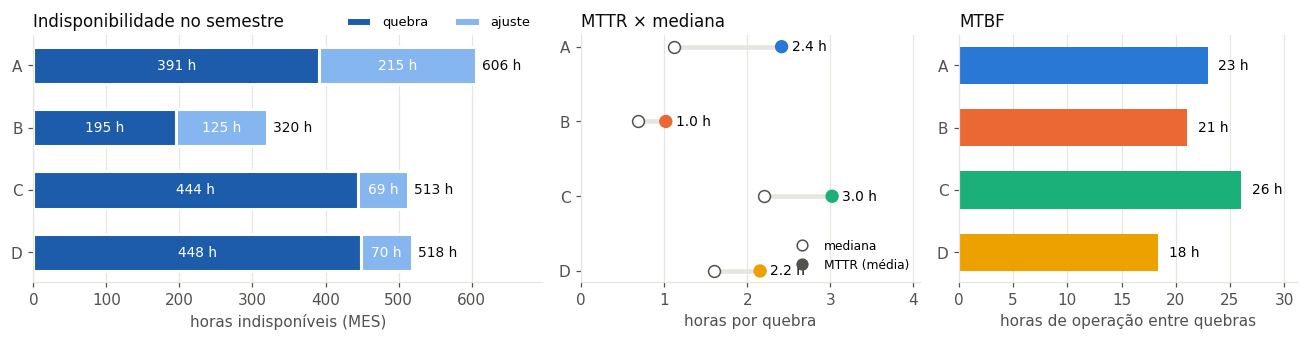

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})

# (a) horas indisponíveis por máquina, quebra × ajuste
h = paradas.pivot_table(index="maquina", columns="tipo_parada", values="duracao_h", aggfunc="sum")[["QUEBRA", "AJUSTE"]]
ax = axes[0]; esq = np.zeros(len(h))
for fam in ["QUEBRA", "AJUSTE"]:
    ax.barh(h.index, h[fam], left=esq, color=COR_FAM[fam], height=0.6, edgecolor="white", linewidth=2, label=fam.lower())
    for i, (x0, w) in enumerate(zip(esq, h[fam])):
        if w > 40:
            ax.text(x0 + w / 2, i, f"{w:.0f} h", ha="center", va="center", color="white", fontsize=9)
    esq += h[fam].to_numpy()
for i, tot in enumerate(esq):
    ax.text(tot + 8, i, f"{tot:.0f} h", va="center", fontsize=9, color=TXT)
ax.invert_yaxis(); ax.set_xlabel("horas indisponíveis (MES)"); ax.grid(axis="y", visible=False)
ax.set_title("Indisponibilidade no semestre")
ax.legend(frameon=False, ncol=2, fontsize=8.5, loc="lower right", bbox_to_anchor=(1.0, 0.98))
ax.set_xlim(0, esq.max() * 1.15)

# (b) MTTR e mediana
ax = axes[1]
k = kpi_maq.loc[MAQS]
y = np.arange(len(MAQS))
ax.hlines(y, k["mediana_reparo_h"], k["MTTR_h"], color=GRADE, lw=3)
ax.scatter(k["mediana_reparo_h"], y, s=60, color="white", edgecolor=TXT2, zorder=3, label="mediana")
ax.scatter(k["MTTR_h"], y, s=60, color=[COR_MAQ[m] for m in MAQS], zorder=3, label="MTTR (média)")
for yi, v in zip(y, k["MTTR_h"]):
    ax.text(v + 0.12, yi, f"{v:.1f} h", va="center", fontsize=9)
ax.set_yticks(y, MAQS); ax.invert_yaxis(); ax.set_xlabel("horas por quebra"); ax.grid(axis="y", visible=False)
ax.set_title("MTTR × mediana")
ax.legend([plt.Line2D([], [], ls="", marker="o", ms=7, mfc="white", mec=TXT2),
           plt.Line2D([], [], ls="", marker="o", ms=7, color=TXT2)], ["mediana", "MTTR (média)"],
          frameon=False, fontsize=8, loc="lower right")
ax.set_xlim(0, k["MTTR_h"].max() * 1.35)

# (c) MTBF
ax = axes[2]
ax.barh(MAQS, k["MTBF_h"], color=[COR_MAQ[m] for m in MAQS], height=0.6)
for yi, v in enumerate(k["MTBF_h"]):
    ax.text(v + 1, yi, f"{v:.0f} h", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("horas de operação entre quebras"); ax.grid(axis="y", visible=False)
ax.set_title("MTBF"); ax.set_xlim(0, k["MTBF_h"].max() * 1.2)

fig.tight_layout(); salvar(fig, "10_retrato_maquinas.png"); plt.show()

**Como ler o painel do meio:** a distância entre o círculo vazio (mediana) e o cheio (média) mostra o quanto a média é puxada por poucas quebras longas. Quanto maior essa distância, menos o MTTR sozinho representa "a quebra típica".

**Leitura dos resultados (base jan–jun/2026):**
- A máquina A é a que **mais perde** (≈ 606 h, disponibilidade ≈ 86%), mas **não é a que mais quebra**: seu MTBF (≈ 23 h) está no meio do grupo. O que a diferencia é o *tempo* por evento e o peso dos ajustes (≈ 1/3 das horas).
- A é também a máquina com **maior distância entre média e mediana** do reparo (2,4 h × 1,1 h): a quebra típica é curta, mas há quebras muito longas. A seção 4 mede isso.
- Para dar escala: MTBF de ≈ 1 dia significa que, em média, cada máquina quebra quase todo dia. É o tamanho do problema de "operar sempre reagindo" descrito no case.

## 2. Evolução mensal

Os mesmos indicadores, mês a mês, em gráficos de linha (uma linha por máquina). Serve para ver se o semestre foi **homogêneo** ou se algum mês concentra a perda, como olhar o extrato do cartão mês a mês em vez de só o total do semestre.


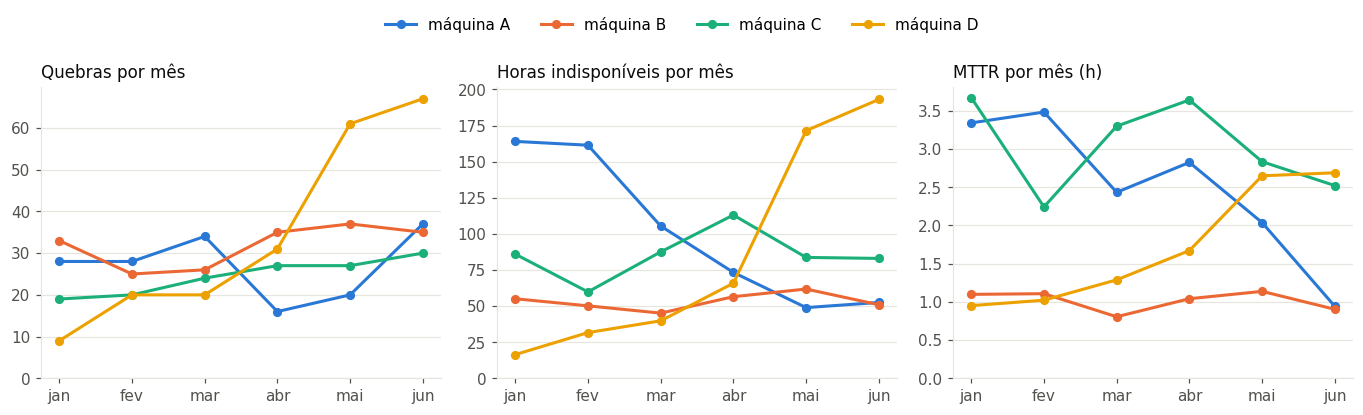

maquina,A,B,C,D
mes_ref,,,,
2026-01,164.00,55.10,86.00,16.40
2026-02,161.40,50.20,59.80,31.70
2026-03,105.40,45.10,87.50,39.80
2026-04,73.30,56.50,113.00,65.80
2026-05,49.00,61.80,83.70,171.50
2026-06,52.50,50.90,83.00,193.10


In [7]:
mensal = (paradas.groupby(["maquina", "mes_ref"])
          .apply(lambda g: pd.Series({"quebras": g["contem_quebra"].sum(),
                                      "horas_indisp": g["duracao_h"].sum(),
                                      "horas_quebra": g.loc[g["contem_quebra"], "duracao_h"].sum(),
                                      "mttr_h": g.loc[g["contem_quebra"] & ~g["micro_parada"], "duracao_h"].mean()}),
                 include_groups=False)
          .reset_index())
meses = sorted(mensal["mes_ref"].unique())
rot_mes = [MES_PT[m.month - 1] for m in meses]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
for ax, col, tit in zip(axes, ["quebras", "horas_indisp", "mttr_h"],
                        ["Quebras por mês", "Horas indisponíveis por mês", "MTTR por mês (h)"]):
    for m in MAQS:
        s = mensal[mensal["maquina"] == m].set_index("mes_ref")[col].reindex(meses)
        ax.plot(range(len(meses)), s.values, marker="o", ms=5, lw=2, color=COR_MAQ[m], label=f"máquina {m}")
    ax.set_xticks(range(len(meses)), rot_mes); ax.set_title(tit)
    ax.grid(axis="x", visible=False); ax.set_ylim(bottom=0)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); salvar(fig, "11_evolucao_mensal.png"); plt.show()

mensal.pivot(index="mes_ref", columns="maquina", values="horas_indisp").round(1)

**Leitura dos resultados:**
- **Máquina A melhorou, mas por um caminho específico.** As horas paradas caíram de ≈ 160 h/mês (jan–fev) para ≈ 50 h/mês (mai–jun), e o MTTR caiu de ≈ 3,4 h para ≈ 1 h. Mas o **número de quebras não caiu** (junho é o mês com mais quebras da A). Ou seja: a equipe ficou **mais rápida para consertar**, mas a **causa** das quebras continua lá. É coerente com o quadro do case (reparo eficiente do sintoma, sem eliminar a causa) e com a reincidência alta da seção 5.
- **Máquina D piorou de forma brusca** a partir de abril: as quebras mensais triplicaram e as horas foram de ≈ 16 h para ≈ 190 h/mês. É o padrão que a seção 6 deve detectar como "deterioração" e funciona como "caso de teste" para o método (D é uma máquina fictícia).
- B e C ficam estáveis no semestre.

## 3. Onde a perda se concentra (Pareto)

**O princípio de Pareto** (ou regra 80/20) diz que, em muitos problemas, **poucas causas respondem pela maior parte do efeito**: 20% dos clientes geram 80% das vendas, 20% das roupas do armário são usadas 80% do tempo. Na manutenção, costuma valer que poucos equipamentos explicam a maior parte das horas paradas.

Se a Engenharia tem tempo limitado, o Pareto mostra **onde cada hora de trabalho rende mais**. Ordenamos equipamentos e componentes por **horas de quebra** (o que a Engenharia pode atacar) e marcamos o ponto em que a soma acumulada passa de 80%. As barras coloridas são os itens que, juntos, chegam a 80%; as cinzas são o resto.

Dois eixos com escalas diferentes no mesmo gráfico fazem o olho "ver" relações que não existem. Em vez da curva, a porcentagem acumulada aparece escrita ao lado de cada barra.

Fazemos em dois níveis:
- **Equipamento:** paradas de quebra (`duracao_h`, sem contar tempo duas vezes).
- **Componente:** registros válidos de QUEBRA (`fim − início`). Cada registro tem um único componente; a sobreposição entre componentes da mesma parada é pequena (≈ 13 h no total da base, ver tratamento inicial).

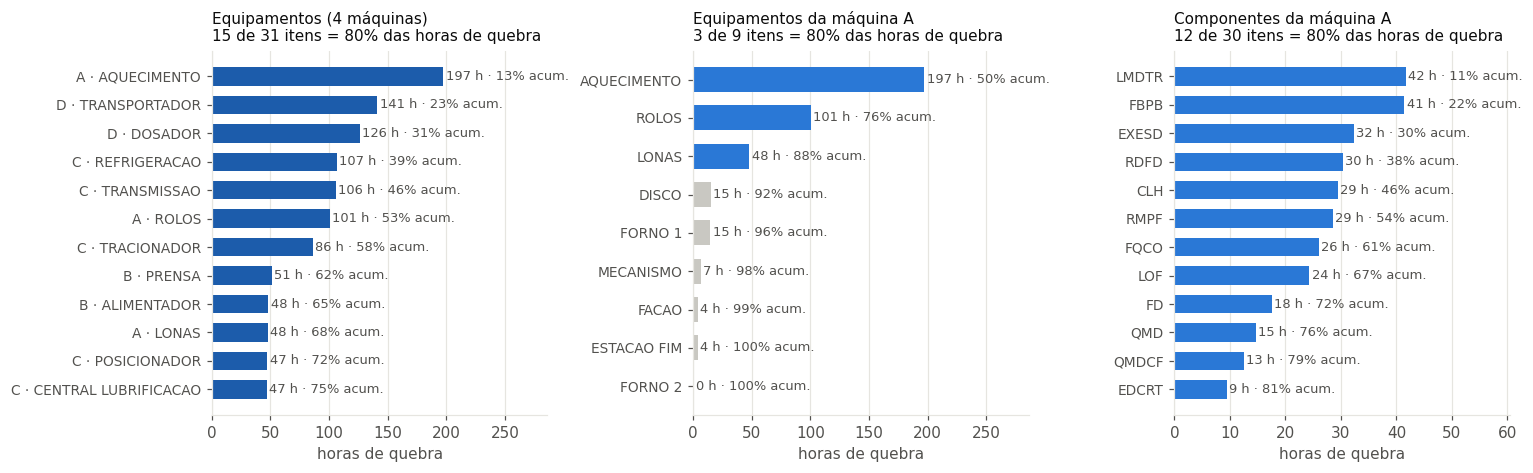

In [8]:
reg_q = mes[mes["valido"] & (mes["familia"] == "QUEBRA")].copy()
reg_q["dur_h"] = (reg_q["fim"] - reg_q["inicio"]).dt.total_seconds() / 3600

def pareto(serie_h):
    s = serie_h.sort_values(ascending=False)
    return pd.DataFrame({"horas": s, "pct": s / s.sum() * 100, "pct_acum": s.cumsum() / s.sum() * 100})

def plot_pareto(ax, par, titulo, cor, top=12):
    p = par.head(top)
    corte = (par["pct_acum"] >= 80).idxmax()             # 1º item que leva o acumulado a ≥ 80%
    n80 = list(par.index).index(corte) + 1
    cores = [cor if i < n80 else NEUTRO for i in range(len(p))]
    ax.barh(range(len(p)), p["horas"], color=cores, height=0.65)
    for i, (h_, a) in enumerate(zip(p["horas"], p["pct_acum"])):
        ax.text(h_ + p["horas"].max() * 0.01, i, f"{h_:.0f} h · {a:.0f}% acum.", va="center", fontsize=8.5, color=TXT2)
    ax.set_yticks(range(len(p)), p.index, fontsize=9); ax.invert_yaxis()
    ax.set_xlim(0, p["horas"].max() * 1.45); ax.grid(axis="y", visible=False)
    ax.set_title(f"{titulo}\n{n80} de {len(par)} itens = 80% das horas de quebra", fontsize=10)
    return n80

par_eq = pareto(quebras.groupby(quebras["maquina"] + " · " + quebras["equipamento"])["duracao_h"].sum())
par_comp_A = pareto(reg_q[reg_q["maquina"] == "A"].groupby("componente")["dur_h"].sum())
par_eq_A = pareto(quebras[quebras["maquina"] == "A"].groupby("equipamento")["duracao_h"].sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
plot_pareto(axes[0], par_eq, "Equipamentos (4 máquinas)", COR_FAM["QUEBRA"])
plot_pareto(axes[1], par_eq_A, "Equipamentos da máquina A", COR_MAQ["A"])
plot_pareto(axes[2], par_comp_A, "Componentes da máquina A", COR_MAQ["A"])
for ax in axes:
    ax.set_xlabel("horas de quebra")
fig.tight_layout(); salvar(fig, "12_pareto.png"); plt.show()

**Leitura dos resultados:**
- Na máquina A, **AQUECIMENTO sozinho responde por metade das horas de quebra**; somando ROLOS e LONAS, chega a ≈ 88%. Os outros seis equipamentos somam ≈ 12%. É um Pareto muito concentrado: três equipamentos são quase todo o problema.
- No nível de componente a perda é mais espalhada (12 de 30 componentes para chegar a 80%), e **o ranking por horas é diferente do ranking por número de quebras**: LMDTR, FBPB e EXESD lideram em horas; CLH, FD e RMPF lideram em quantidade (seção 5). São dois tipos de problema diferentes:
  - **poucas quebras longas** → atacar o tempo de reparo (peça em estoque, diagnóstico, procedimento);
  - **muitas quebras curtas e repetidas** → atacar a causa raiz.

### 3.1 A concentração muda ao longo do semestre?

O gráfico abaixo é um **mapa de calor**: uma tabela em que cada célula é pintada com intensidade proporcional ao valor, como um mapa de temperatura. Linhas = equipamentos da máquina A; colunas = meses; quanto mais escuro o azul, mais horas de quebra naquele equipamento naquele mês.

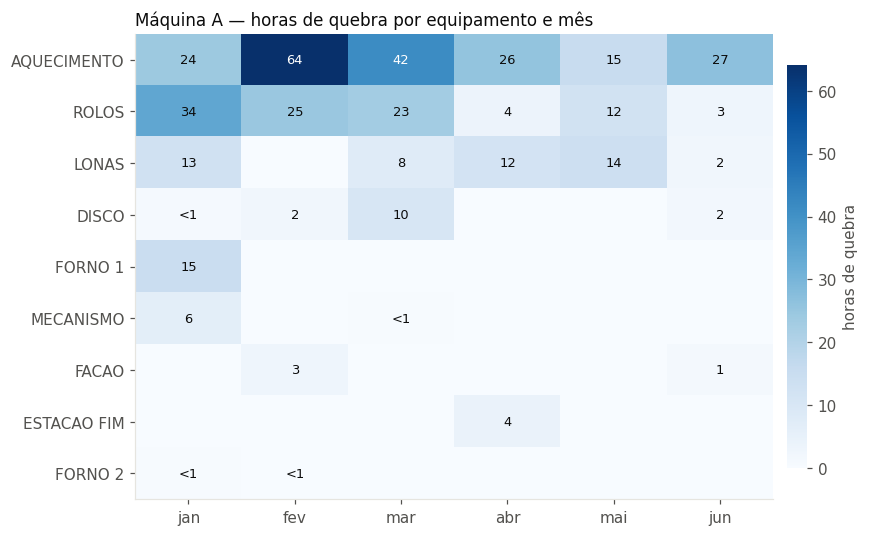

In [9]:
hm = (quebras[quebras["maquina"] == "A"]
      .pivot_table(index="equipamento", columns="mes_ref", values="duracao_h", aggfunc="sum", fill_value=0))
hm = hm.loc[hm.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 0.42 * len(hm) + 1.2))
im = ax.imshow(hm.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(hm.shape[1]), [MES_PT[m.month - 1] for m in hm.columns])
ax.set_yticks(range(hm.shape[0]), hm.index)
ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        if v > 0:
            ax.text(j, i, f"{v:.0f}" if v >= 1 else "<1", ha="center", va="center", fontsize=8.5,
                    color="white" if v > hm.values.max() * 0.55 else TXT)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label("horas de quebra"); cb.outline.set_visible(False)
ax.set_title("Máquina A — horas de quebra por equipamento e mês")
fig.tight_layout(); salvar(fig, "13_mapa_calor_A.png"); plt.show()

**Leitura:** a queda de horas da A vista na seção 2 vem principalmente de **ROLOS** (23–34 h/mês no 1º trimestre, 3–12 h/mês a partir de abril) e do pico de **AQUECIMENTO** em fevereiro–março, que não se repetiu. AQUECIMENTO, porém, continua sendo o maior consumidor de horas em quase todos os meses.

## 4. Distribuição do tempo de reparo

O MTTR resume centenas de reparos em **um número só**. Aqui mostramos todos eles de uma vez, para ver o "formato" dos tempos de reparo.

**Como ler o gráfico de caixa (*boxplot*):** cada máquina tem uma "caixa".
- A **linha preta** dentro da caixa é a mediana (o reparo do meio da fila).
- A **caixa** contém a **metade central** dos reparos (do 25º ao 75º da fila, em cada 100).
- As **hastes** vão até os valores ainda considerados normais, e os **pontinhos** são reparos fora do comum.

**Por que o eixo está em escala logarítmica:** os reparos vão de poucos minutos a mais de 14 horas. Num eixo comum, todos os reparos curtos ficariam espremidos num cantinho. Na escala logarítmica, **cada passo do eixo multiplica o valor** (10 min, 100 min, 1.000 min) em vez de somar, como na escala Richter dos terremotos. Assim dá para ver os curtos e os longos no mesmo gráfico.

As linhas tracejadas marcam 30 min, 1 h, 4 h e 8 h (um turno inteiro).

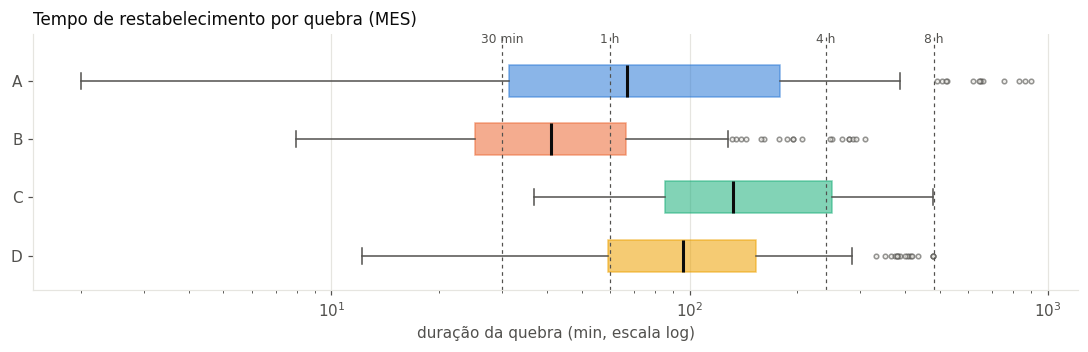

,n,mean,std,min,25%,mediana,75%,90%,max,pct_acima_4h,horas_em_quebras_4h
maquina,,,,,,,,,,,
A,162.00,2.41,3.09,0.03,0.52,1.12,2.99,6.22,14.92,19.14,61.37
B,191.00,1.02,0.98,0.13,0.42,0.68,1.11,2.13,5.14,4.19,18.87
C,147.00,3.02,2.09,0.61,1.42,2.20,4.15,6.73,7.95,25.17,52.06
D,208.00,2.15,1.72,0.20,0.99,1.60,2.56,4.45,7.95,14.90,38.93


In [10]:
rep = quebras[~quebras["micro_parada"]]
fig, ax = plt.subplots(figsize=(10, 3.3))
dados = [rep.loc[rep["maquina"] == m, "duracao_h"] * 60 for m in MAQS]
kw = {"orientation": "horizontal"} if tuple(map(int, plt.matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}
bp = ax.boxplot(dados, **kw, widths=0.55, patch_artist=True, showfliers=True,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRADE, markeredgecolor=TXT2, alpha=0.6),
                medianprops=dict(color=TXT, lw=2), whiskerprops=dict(color=TXT2), capprops=dict(color=TXT2))
for patch, m in zip(bp["boxes"], MAQS):
    patch.set_facecolor(COR_MAQ[m]); patch.set_alpha(0.55); patch.set_edgecolor(COR_MAQ[m])
ax.set_xscale("log")
for ref, lab in [(30, "30 min"), (60, "1 h"), (240, "4 h"), (480, "8 h")]:
    ax.axvline(ref, color=TXT2, lw=0.8, ls=(0, (3, 3)))
    ax.text(ref, 0.35, lab, ha="center", fontsize=8, color=TXT2)
ax.set_yticks(range(1, 5), MAQS); ax.invert_yaxis(); ax.set_ylim(4.6, 0.2)
ax.set_xlabel("duração da quebra (min, escala log)"); ax.grid(axis="y", visible=False)
ax.set_title("Tempo de restabelecimento por quebra (MES)")
fig.tight_layout(); salvar(fig, "14_distribuicao_reparo.png"); plt.show()

(rep.groupby("maquina")["duracao_h"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .assign(pct_acima_4h=rep.groupby("maquina")["duracao_h"].apply(lambda s: (s > 4).mean() * 100),
            horas_em_quebras_4h=rep.groupby("maquina")["duracao_h"].apply(lambda s: s[s > 4].sum() / s.sum() * 100))
    .rename(columns={"count": "n", "50%": "mediana"}))

**Sobre a tabela:** as colunas `25%`, `mediana`, `75%` e `90%` são **percentis**: o percentil 90, por exemplo, é o tempo abaixo do qual ficam 90% dos reparos (só 1 em cada 10 demora mais que isso). A coluna `horas_em_quebras_4h` responde "**que parte das horas de quebra vem das quebras longas** (mais de 4 h)". Se uma pequena fração das quebras responde por grande parte das horas, reduzir *o tempo das quebras longas* (peça em estoque, procedimento, diagnóstico) rende mais do que reduzir o número de quebras curtas.

**Leitura dos resultados:** na máquina A, **≈ 19% das quebras duram mais de 4 h e somam ≈ 61% das horas de quebra**, a maior concentração das quatro máquinas. Na prática: **uma em cada cinco quebras da A vira um evento de meio turno**, e é ali que está a maior parte da perda. Entender o que essas quebras longas têm em comum (equipamento, componente, turno, texto do SAP) é uma análise de causa raiz de alto retorno. A tabela `ind_quebras`, exportada na seção 12, permite filtrá-las diretamente.

## 5. Reincidência

**Definição:** uma quebra de um componente é **reincidente** se o mesmo componente (mesma máquina e equipamento) já tinha quebrado antes, a até $D$ dias. Usamos duas janelas:

- $D$ = **7 dias**: reincidência **imediata**, sinal de que o reparo não resolveu;
- $D$ = **30 dias**: reincidência **crônica**, o problema fica voltando.

**Detalhes das decisões:**
- O intervalo é medido do **fim** da quebra anterior até o **início** da atual, ou seja, conta só o tempo em que o componente esteve funcionando, e não o tempo de conserto.
- Trabalhamos com os **registros** do MES, porque é no registro que fica o componente.
- Se o mesmo componente aparece duas vezes **dentro da mesma parada**, isso não conta como reincidência: é a mesma quebra.

In [11]:
r = (reg_q.sort_values(["maquina", "equipamento", "componente", "inicio"])
          .drop_duplicates(["id_parada", "componente"]).copy())
chave_comp = ["maquina", "equipamento", "componente"]
r["fim_anterior"] = r.groupby(chave_comp)["fim"].shift()
r["intervalo_d"] = (r["inicio"] - r["fim_anterior"]).dt.total_seconds() / 86400
r["reinc_7d"] = r["intervalo_d"] <= 7
r["reinc_30d"] = r["intervalo_d"] <= 30

reinc_maq = r.groupby("maquina").agg(quebras_componente=("id_registro", "size"),
                                     reinc_7d=("reinc_7d", "sum"), reinc_30d=("reinc_30d", "sum"),
                                     intervalo_mediano_d=("intervalo_d", "median"))
reinc_maq["%_7d"] = reinc_maq["reinc_7d"] / reinc_maq["quebras_componente"] * 100
reinc_maq["%_30d"] = reinc_maq["reinc_30d"] / reinc_maq["quebras_componente"] * 100
reinc_maq

,quebras_componente,reinc_7d,reinc_30d,intervalo_mediano_d,%_7d,%_30d
maquina,,,,,,
A,168,87,117,4.40,51.79,69.64
B,191,56,122,13.55,29.32,63.87
C,149,33,94,14.70,22.15,63.09
D,214,91,158,7.12,42.52,73.83


### Como ler os gráficos de reincidência

**Painel da esquerda (curva acumulada):** para cada máquina, cada ponto da curva responde "**que porcentagem** das quebras aconteceu **em até X dias** depois da quebra anterior do mesmo componente?". Por exemplo, se a curva passa por (7 dias, 50%), metade das quebras veio em até uma semana. O eixo dos dias está em escala logarítmica (cada passo multiplica o valor), para mostrar com detalhe os intervalos curtos.

**Painel da direita:** os 12 componentes da máquina A que mais quebram, com cada barra dividida em: reincidências em até 7 dias (cor forte), entre 8 e 30 dias (cor clara) e primeiras quebras ou depois de 30 dias (cinza).

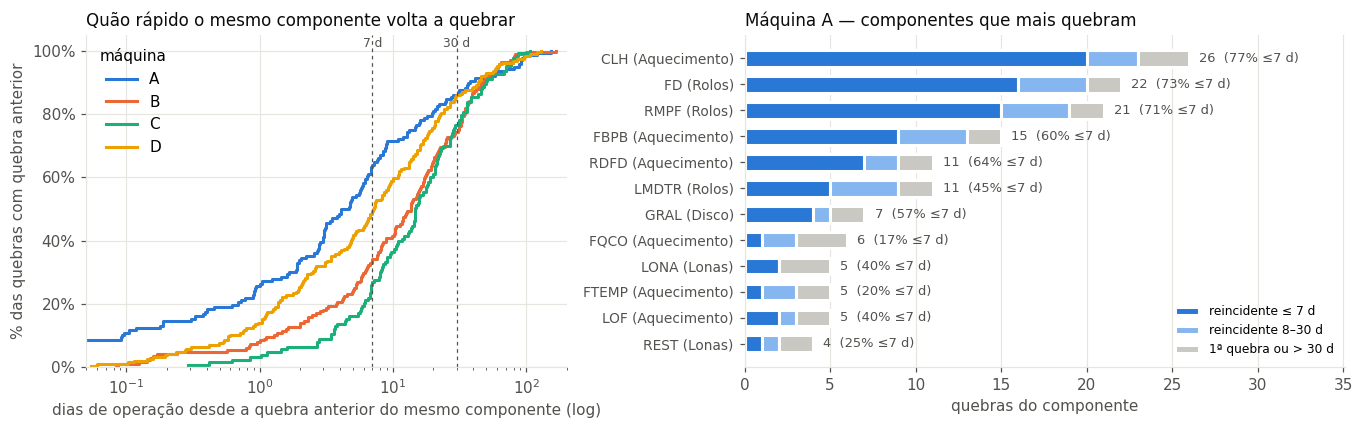

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0), gridspec_kw={"width_ratios": [1, 1.25]})

# (a) curva acumulada (ECDF) dos intervalos entre quebras do mesmo componente
ax = axes[0]
for m in MAQS:
    x = np.sort(r.loc[(r["maquina"] == m), "intervalo_d"].dropna())
    ax.step(x, np.arange(1, len(x) + 1) / len(x) * 100, where="post", lw=2, color=COR_MAQ[m], label=m)
for ref in (7, 30):
    ax.axvline(ref, color=TXT2, lw=0.8, ls=(0, (3, 3)))
    ax.text(ref, 101, f"{ref} d", ha="center", fontsize=8, color=TXT2)
ax.set_xscale("log"); ax.set_xlim(0.05, 200); ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("dias de operação desde a quebra anterior do mesmo componente (log)")
ax.set_ylabel("% das quebras com quebra anterior"); ax.legend(frameon=False, title="máquina", loc="upper left")
ax.set_title("Quão rápido o mesmo componente volta a quebrar")

# (b) componentes da máquina A com mais quebras, separando as reincidentes em ≤7 d
ax = axes[1]
ca = (r[r["maquina"] == "A"].groupby(["equipamento", "componente"])
      .agg(n=("id_registro", "size"), r7=("reinc_7d", "sum"), r30=("reinc_30d", "sum")))
ca = ca.sort_values("n", ascending=False).head(12)
rot = [f"{c} ({e.title()})" for e, c in ca.index]
yy = np.arange(len(ca))
seg = [("r7", "reincidente ≤ 7 d", COR_MAQ["A"]),
       ("r30_only", "reincidente 8–30 d", "#86b6ef"),
       ("rest", "1ª quebra ou > 30 d", NEUTRO)]
ca["r30_only"] = ca["r30"] - ca["r7"]; ca["rest"] = ca["n"] - ca["r30"]
esq = np.zeros(len(ca))
for col, lab, cor in seg:
    ax.barh(yy, ca[col], left=esq, color=cor, height=0.65, edgecolor="white", linewidth=2, label=lab)
    esq += ca[col].to_numpy()
for i, (n_, r7) in enumerate(zip(ca["n"], ca["r7"])):
    ax.text(n_ + 0.6, i, f"{n_:.0f}  ({r7 / n_ * 100:.0f}% ≤7 d)", va="center", fontsize=8.5, color=TXT2)
ax.set_yticks(yy, rot, fontsize=9); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, ca["n"].max() * 1.35); ax.set_xlabel("quebras do componente")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Máquina A — componentes que mais quebram")
fig.tight_layout(); salvar(fig, "15_reincidencia.png"); plt.show()

**Como ler o painel da esquerda:** uma curva que sobe cedo (à esquerda) indica que o componente volta a quebrar logo depois do reparo, sintoma típico de reparo que trata o efeito e não a causa. É exatamente o "ciclo de reparo, retorno e nova falha" descrito no case.

A tabela abaixo lista os componentes (de todas as máquinas) com pelo menos 5 quebras, ordenados pela taxa de reincidência em 7 dias. 🔧 O mínimo de 5 quebras evita que um componente com 2 quebras (e 1 reincidência = "50%") apareça no topo só por acaso.

In [13]:
tab_reinc = (r.groupby(chave_comp)
               .agg(quebras=("id_registro", "size"), reinc_7d=("reinc_7d", "sum"), reinc_30d=("reinc_30d", "sum"),
                    intervalo_mediano_d=("intervalo_d", "median"), horas=("dur_h", "sum")))
tab_reinc["%_7d"] = tab_reinc["reinc_7d"] / tab_reinc["quebras"] * 100
tab_reinc["%_30d"] = tab_reinc["reinc_30d"] / tab_reinc["quebras"] * 100
tab_reinc[tab_reinc["quebras"] >= 5].sort_values(["%_7d", "quebras"], ascending=False).head(15)

quebras  reinc_7d  reinc_30d  \
maquina equipamento   componente                                 
D       TRANSPORTADOR TRP-MAN          28        22         26   
A       AQUECIMENTO   CLH              26        20         23   
        ROLOS         FD               22        16         20   
D       DOSADOR       DOS-ATU          29        21         27   
A       ROLOS         RMPF             21        15         19   
B       ALIMENTADOR   ALM-COR          20        13         19   
D       TRANSPORTADOR TRP-MOT          14         9         12   
A       AQUECIMENTO   RDFD             11         7          9   
                      FBPB             15         9         13   
D       ROSCA SEM FIM RSF-RED           5         3          3   
A       DISCO         GRAL              7         4          5   
D       DOSADOR       DOS-VLV          13         7         10   
C       TRANSMISSAO   TRM-EIX          15         8         13   
D       DOSADOR       DOS-SEN           8         4          7   
B       EXTRACAO      EXT-MAN           6         3          4   

                                  intervalo_mediano_d  horas  %_7d  %_30d  
maquina equipamento   componente                                           
D       TRANSPORTADOR TRP-MAN                    1.98  74.99 78.57  92.86  
A       AQUECIMENTO   CLH                        3.13  20.53 76.92  88.46  
        ROLOS         FD                         2.82  17.32 72.73  90.91  
D       DOSADOR       DOS-ATU                    2.00  53.48 72.41  93.10  
A       ROLOS         RMPF                       2.91  25.12 71.43  90.48  
B       ALIMENTADOR   ALM-COR                    4.26  15.46 65.00  95.00  
D       TRANSPORTADOR TRP-MOT                    3.08  23.95 64.29  85.71  
A       AQUECIMENTO   RDFD                       5.60  20.93 63.64  81.82  
                      FBPB                       6.26  26.67 60.00  86.67  
D       ROSCA SEM FIM RSF-RED                    5.27   6.74 60.00  60.00  
A       DISCO         GRAL                       0.41   2.48 57.14  71.43  
D       DOSADOR       DOS-VLV                    6.26  41.30 53.85  76.92  
C       TRANSMISSAO   TRM-EIX                    6.44  37.40 53.33  86.67  
D       DOSADOR       DOS-SEN                    6.08  27.28 50.00  87.50  
B       EXTRACAO      EXT-MAN                    6.99   7.46 50.00  66.67

**Leitura dos resultados:**
- **A máquina A tem a reincidência mais rápida das quatro:** ≈ 52% das quebras de componente repetem o mesmo componente em até 7 dias (B: 29%, C: 22%, D: 43%), e o intervalo mediano entre quebras do mesmo componente é de ≈ 4 dias. Na curva da esquerda, a linha da A é a primeira a subir.
- Os campeões de reincidência imediata da A são **CLH (Aquecimento), FD e RMPF (Rolos)**: mais de 70% das quebras de cada um voltam em até uma semana. São componentes de quebras **curtas** (mediana < 40 min), por isso pesam pouco no Pareto de horas, mas são exatamente o "ciclo de reparo, retorno e nova falha" que o case descreve.
- É esse o número que sustenta, para a Engenharia, a afirmação de que "o reparo trata o efeito": para esses componentes, a próxima quebra é mais provável na semana seguinte do que em qualquer outro momento.

## 6. Sinais de deterioração

O case não pede para prever a data da próxima quebra, e sim identificar **três sinais de piora**: quebras ficando mais frequentes, intervalos entre elas ficando mais curtos e reparos ficando mais demorados. Para cada sinal usamos um teste estatístico simples, aplicado a cada equipamento com pelo menos 8 quebras no semestre (com menos que isso, qualquer "tendência" pode ser só acaso).

### Antes de tudo: o que é um "teste estatístico" e o tal "p"

Um teste estatístico responde: **"isso que eu estou vendo pode ter acontecido só por sorte?"**. Se você joga uma moeda 10 vezes e sai 6 caras, é sorte normal. Se sai 10 caras, é muito difícil ser sorte: a moeda provavelmente está viciada.

O **p-valor** (ou só **p**) é a chance de ver um resultado tão extremo **se nada estivesse acontecendo** (moeda honesta, máquina estável). Convenção usual: se **p < 0,05** (menos de 5% de chance de ser sorte), dizemos que o resultado é **significativo**, ou seja, que há evidência de um efeito real. 10 caras seguidas têm p ≈ 0,001: significativo.

### Os testes usados

| Sinal | Ferramenta | Como ler |
|---|---|---|
| Quebras ficando mais frequentes | **Teste de Laplace** sobre os instantes das quebras $t_1,\dots,t_n$ no período $[0, T]$: $U = \dfrac{\bar t - T/2}{T\sqrt{1/(12n)}}$ | $U > 1{,}645$ → frequência **aumentando** (com 95% de confiança); $U < -1{,}645$ → **diminuindo**; no meio, nenhuma tendência detectável. |
| Intervalo entre quebras encolhendo | razão (tempo médio entre quebras no 2º trimestre) ÷ (no 1º trimestre) | Menor que 1 → os intervalos ficaram mais curtos. |
| Reparos ficando mais longos | **correlação de Spearman** entre a data da quebra e a sua duração | $\rho > 0$ com $p < 0{,}05$ → os reparos estão demorando mais com o passar do tempo. |
| Tipo de padrão de falha | **parâmetro de forma β de Weibull**, ajustado aos intervalos entre quebras | $\beta < 1$: quebras **agrupadas** (voltam logo após o reparo); $\beta \approx 1$: **aleatórias**; $\beta > 1$: **desgaste** (o risco cresce com o uso, e preventiva por tempo faz sentido). |

**Teste de Laplace, com uma gangorra:** coloque o período de seis meses numa régua e um pesinho em cada data de quebra. Se as quebras estão espalhadas por igual, a régua se equilibra **no meio**. Se elas se acumulam no fim do semestre, a régua pende para a direita. O $U$ mede **o quanto o ponto de equilíbrio se afastou do meio**, descontando o que seria esperado por puro acaso (quanto menos quebras, mais o acaso pesa, por isso o $n$ na fórmula). O valor 1,645 é o limite a partir do qual o desvio tem menos de 5% de chance de ser sorte, olhando só para um lado (só para "piorando").

Laplace é o teste clássico para tendência em **equipamentos que são consertados e voltam a funcionar** (Ascher & Feingold, 1984; norma IEC 60605-6). É simples, transparente e só precisa das datas das quebras.

**Correlação de Spearman:** mede se duas coisas **sobem juntas**. Em vez de usar os valores em si, ela usa as **posições** (1º, 2º, 3º...), por isso não se deixa enganar por um reparo absurdamente longo. $\rho$ vai de −1 a +1: perto de +1, "quanto mais tarde no semestre, mais longo o reparo"; perto de 0, nenhuma relação; perto de −1, os reparos estão encurtando.

**Weibull β, o "formato" da falha:** pense em três coisas que "quebram":
- uma **lâmpada nova com defeito de fábrica** costuma queimar logo, e se sobreviver dura muito (β < 1, falhas agrupadas no começo);
- um **pneu furado por um prego** pode acontecer a qualquer momento, independentemente da idade (β ≈ 1, aleatório);
- uma **sola de sapato** se gasta com o uso, e a chance de furar cresce com o tempo (β > 1, desgaste).

Saber o "formato" diz **qual estratégia de manutenção funciona**: trocar peças em intervalos fixos só ajuda no caso do desgaste.

In [14]:
def laplace_U(t_h, T):
    n = len(t_h)
    return (np.mean(t_h) - T / 2) / (T * np.sqrt(1 / (12 * n))) if n >= 3 else np.nan

def deterioracao(g, T=T_H, ini=T_INI):
    g = g.sort_values("inicio")
    t = (g["inicio"] - ini).dt.total_seconds().to_numpy() / 3600
    n = len(g)
    tbf = (g["inicio"].iloc[1:].to_numpy() - g["fim"].iloc[:-1].to_numpy()) / np.timedelta64(1, "h")
    tbf = tbf[tbf > 0]
    meio = ini + pd.Timedelta(hours=T / 2)
    n1, n2 = (g["inicio"] < meio).sum(), (g["inicio"] >= meio).sum()
    rho, p_rho = stats.spearmanr(t, g["duracao_h"]) if n >= 5 else (np.nan, np.nan)
    beta = stats.weibull_min.fit(tbf, floc=0)[0] if len(tbf) >= 8 else np.nan
    return pd.Series({
        "quebras": n, "quebras_1o_tri": n1, "quebras_2o_tri": n2,
        "U_laplace": laplace_U(t, T),
        "razao_intervalo_2o_1o": (T / 2 / max(n2, 1)) / (T / 2 / max(n1, 1)),
        "rho_reparo": rho, "p_reparo": p_rho,
        "beta_weibull": beta,
        "MTTR_1o_tri": g.loc[g["inicio"] < meio, "duracao_h"].mean(),
        "MTTR_2o_tri": g.loc[g["inicio"] >= meio, "duracao_h"].mean(),
    })

det = (quebras.groupby(["maquina", "equipamento"]).filter(lambda g: len(g) >= 8)
              .groupby(["maquina", "equipamento"]).apply(deterioracao, include_groups=False))
det_maq = quebras.groupby("maquina").apply(deterioracao, include_groups=False)

def alertas(row):
    """Sinais de piora (alertas) e de melhora/padrão (informativos), separados."""
    piora, info = [], []
    if row["U_laplace"] > 1.645: piora.append("frequência ↑")
    if row["rho_reparo"] > 0 and row["p_reparo"] < 0.05: piora.append("reparo mais longo")
    if row["U_laplace"] < -1.645: info.append("frequência ↓")
    if row["rho_reparo"] < 0 and row["p_reparo"] < 0.05: info.append("reparo mais curto")
    if row["beta_weibull"] < 0.8: info.append("quebras agrupadas")
    if row["beta_weibull"] > 1.2: info.append("padrão de desgaste")
    return pd.Series({"alertas": ", ".join(piora), "observacoes": ", ".join(info)})

det = det.join(det.apply(alertas, axis=1))
det_maq = det_maq.join(det_maq.apply(alertas, axis=1))

# nível máquina
det_maq.round(2)

,quebras,quebras_1o_tri,quebras_2o_tri,U_laplace,razao_intervalo_2o_1o,rho_reparo,p_reparo,beta_weibull,MTTR_1o_tri,MTTR_2o_tri,alertas,observacoes
maquina,,,,,,,,,,,,
A,163.00,90.00,73.00,-0.01,1.23,-0.26,0.00,0.71,3.00,1.65,,"reparo mais curto, quebras agrupadas"
B,191.00,84.00,107.00,1.05,0.79,-0.04,0.57,0.86,1.01,1.03,,
C,147.00,64.00,83.00,2.16,0.77,-0.11,0.17,0.88,3.12,2.95,frequência ↑,
D,208.00,50.00,158.00,8.36,0.32,0.42,0.00,0.75,1.14,2.48,"frequência ↑, reparo mais longo",quebras agrupadas


Agora o mesmo quadro no nível de **equipamento** (só os que têm 8 ou mais quebras), ordenado pelo $U$ do teste de Laplace (os que mais pioram no topo).

A coluna `alertas` traz só sinais de **piora** (o que pede ação). A coluna `observacoes` traz sinais de **melhora** e o padrão de falha indicado pelo β (quebras agrupadas ou desgaste).

In [15]:
det.sort_values("U_laplace", ascending=False).round(2)

quebras  quebras_1o_tri  quebras_2o_tri  \
maquina equipamento                                                     
D       TRANSPORTADOR           55.00            8.00           47.00   
        DOSADOR                 53.00            9.00           44.00   
        EXAUSTAO                17.00            4.00           13.00   
        BASCULADOR              11.00            2.00            9.00   
        PAINEL ELETRICO         11.00            3.00            8.00   
A       DISCO                   12.00            5.00            7.00   
C       REFRIGERACAO            37.00           15.00           22.00   
D       ROSCA SEM FIM           20.00            8.00           12.00   
B       ALIMENTADOR             53.00           19.00           34.00   
C       POSICIONADOR            14.00            4.00           10.00   
D       VIBRADOR                18.00            8.00           10.00   
C       TRANSMISSAO             33.00           14.00           19.00   
B       HIDRAULICA              38.00           15.00           23.00   
D       ELEVADOR                23.00            8.00           15.00   
A       AQUECIMENTO             68.00           35.00           33.00   
C       CENTRAL LUBRIFICACAO    15.00            6.00            9.00   
B       EXTRACAO                17.00            8.00            9.00   
A       LONAS                   14.00            6.00            8.00   
C       TRACIONADOR             31.00           14.00           17.00   
B       PRENSA                  47.00           22.00           25.00   
C       EMPILHADOR              12.00            8.00            4.00   
A       ROLOS                   59.00           37.00           22.00   
B       GUIAMENTO               26.00           16.00           10.00   

                              U_laplace  razao_intervalo_2o_1o  rho_reparo  \
maquina equipamento                                                          
D       TRANSPORTADOR              5.34                   0.17        0.52   
        DOSADOR                    5.07                   0.20        0.26   
        EXAUSTAO                   2.69                   0.31        0.13   
        BASCULADOR                 2.60                   0.22        0.14   
        PAINEL ELETRICO            2.24                   0.38        0.56   
A       DISCO                      2.17                   0.71       -0.71   
C       REFRIGERACAO               1.87                   0.68       -0.02   
D       ROSCA SEM FIM              1.66                   0.67        0.52   
B       ALIMENTADOR                1.63                   0.56        0.02   
C       POSICIONADOR               1.29                   0.40        0.04   
D       VIBRADOR                   1.21                   0.80        0.35   
C       TRANSMISSAO                1.16                   0.74       -0.20   
B       HIDRAULICA                 1.00                   0.65        0.08   
D       ELEVADOR                   0.93                   0.53        0.41   
A       AQUECIMENTO                0.78                   1.06       -0.23   
C       CENTRAL LUBRIFICACAO       0.67                   0.67        0.00   
B       EXTRACAO                   0.65                   0.89        0.03   
A       LONAS                      0.49                   0.75       -0.29   
C       TRACIONADOR                0.34                   0.82       -0.26   
B       PRENSA                     0.04                   0.88        0.04   
C       EMPILHADOR                -0.54                   2.00       -0.53   
A       ROLOS                     -1.54                   1.68       -0.25   
B       GUIAMENTO                 -1.66                   1.60       -0.40   

                              p_reparo  beta_weibull  MTTR_1o_tri  \
maquina equipamento                                                 
D       TRANSPORTADOR             0.00          0.69         1.21   
        DOSADOR                   0.06        

**Como ler a figura abaixo:**

- **Painel da esquerda:** cada bolinha é um equipamento, posicionada pelo seu $U$ (o "quanto a gangorra pende"). A **faixa cinza** no meio (entre −1,645 e +1,645) é a zona de "nada detectável". Bolinhas à direita da faixa: frequência aumentando; à esquerda: diminuindo. O tamanho da bolinha é o número de quebras.
- **Painel da direita:** quebras **acumuladas** ao longo do semestre para os 4 equipamentos da máquina A com mais quebras (explicação logo abaixo).

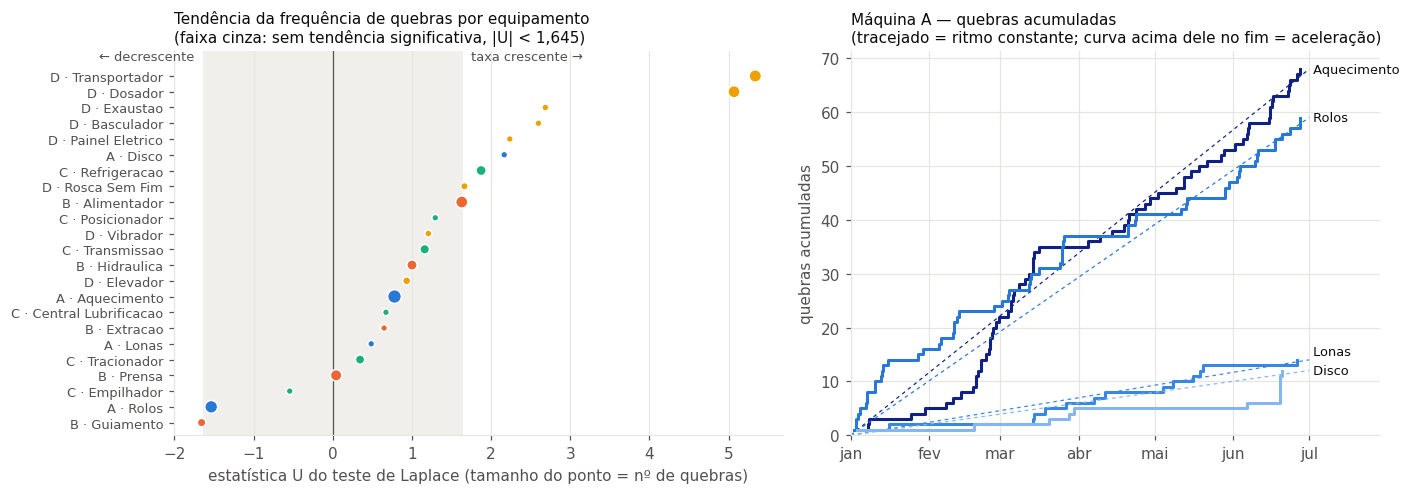

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

# (a) U de Laplace por equipamento, com faixas de decisão
ax = axes[0]
d = det.sort_values("U_laplace")
rot = [f"{m} · {e.title()}" for m, e in d.index]
ax.axvspan(-1.645, 1.645, color=GRADE, alpha=0.6, lw=0)
ax.axvline(0, color=TXT2, lw=0.8)
ax.scatter(d["U_laplace"], range(len(d)), s=[max(20, q * 1.2) for q in d["quebras"]],
           color=[COR_MAQ[m] for m, _ in d.index], zorder=3, edgecolor="white", linewidth=1)
ax.set_yticks(range(len(d)), rot, fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_ylim(-0.8, len(d) + 0.6)
ax.text(1.75, len(d) - 0.2, "taxa crescente →", fontsize=8.5, color=TXT2, va="bottom")
ax.text(-1.75, len(d) - 0.2, "← decrescente", fontsize=8.5, color=TXT2, ha="right", va="bottom")
ax.set_xlabel("estatística U do teste de Laplace (tamanho do ponto = nº de quebras)")
ax.set_title("Tendência da frequência de quebras por equipamento\n"
             "(faixa cinza: sem tendência significativa, |U| < 1,645)", fontsize=10)

# (b) curva acumulada de quebras da máquina A por equipamento
ax = axes[1]
eqA = det.loc["A"].sort_values("quebras", ascending=False).index[:4]
tons = ["#0f2185", "#2a78d6", "#3987e5", "#86b6ef"]
y_rot = []
for e, cor in zip(eqA, tons):
    g = quebras[(quebras["maquina"] == "A") & (quebras["equipamento"] == e)].sort_values("inicio")
    ax.step(g["inicio"], np.arange(1, len(g) + 1), where="post", lw=2, color=cor, label=e.title())
    ax.plot([T_INI, T_FIM], [0, len(g)], color=cor, lw=0.8, ls=(0, (3, 3)))
    y_rot.append([len(g), e.title()])
y_rot.sort()                                   # afasta rótulos que cairiam um em cima do outro
for i in range(1, len(y_rot)):
    y_rot[i][0] = max(y_rot[i][0], y_rot[i - 1][0] + 3.5)
for yv, nome in y_rot:
    ax.text(T_FIM, yv, f" {nome}", va="center", fontsize=8.5, color=TXT)
ax.set_xlim(T_INI, T_FIM + pd.Timedelta(days=28))
eixo_meses(ax)
ax.set_ylabel("quebras acumuladas"); ax.set_ylim(bottom=0)
ax.set_title("Máquina A — quebras acumuladas\n(tracejado = ritmo constante; curva acima dele no fim = aceleração)", fontsize=10)
fig.tight_layout(); salvar(fig, "16_deterioracao.png"); plt.show()

**Como ler o painel da direita:** a "escada" sobe um degrau a cada quebra. Se a máquina quebrasse sempre no mesmo ritmo, a escada seguiria a **reta tracejada**. Uma escada que fica **abaixo** da reta no começo e a alcança no fim está **acelerando** (o mesmo que $U > 0$). Uma escada **acima** da reta no começo está **desacelerando**.

**Limitação:** seis meses é pouco para enxergar tendência. O teste detecta mudanças **fortes**; a ausência de alerta **não prova** que está tudo estável. Com o histórico acumulado pelo acionamento digital (Subproduto 1), os mesmos testes passam a rodar em **janela móvel** (por exemplo, sempre os últimos 6 meses, recalculados todo mês) e viram alerta automático no dashboard.

### 6.1 Evolução do intervalo entre quebras: estável × em deterioração

Outra forma de ver a mesma coisa. Cada ponto é **quanto tempo o equipamento funcionou entre duas quebras seguidas**; a linha preta é a **mediana móvel** de 7 intervalos.

**Mediana móvel:** em cada ponto, pegamos os 7 intervalos mais recentes e calculamos o valor do meio. É como a "média dos últimos jogos" de um time: suaviza os altos e baixos de um jogo isolado e mostra a tendência.

Colocamos lado a lado os dois equipamentos que mais quebram na máquina A e os dois com maior $U$ de toda a base (máquina D). Em deterioração, a linha **desce** de forma sustentada: o equipamento aguenta cada vez menos tempo entre uma quebra e outra. O eixo vertical está em escala logarítmica (cada passo multiplica o valor).

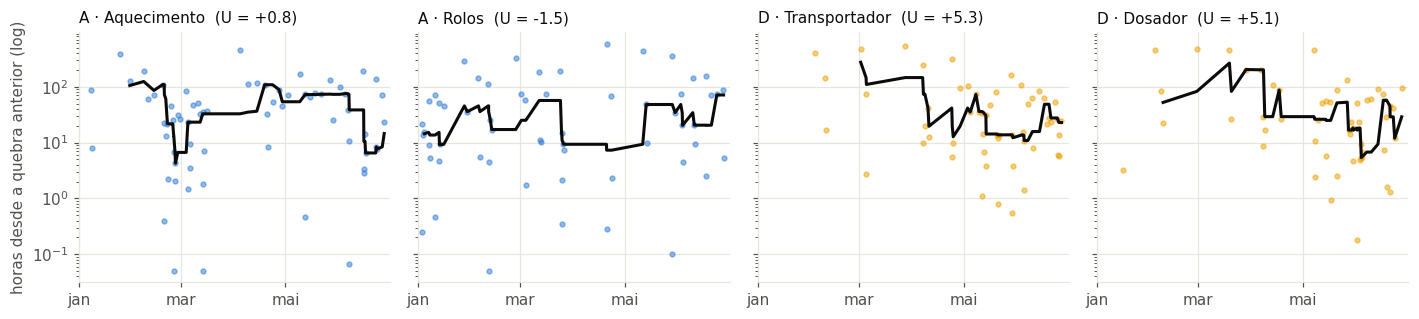

In [17]:
pares_tbf = [("A", eqA[0]), ("A", eqA[1])] + list(det.sort_values("U_laplace", ascending=False).index[:2])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.0), sharey=True)
for ax, (m, e) in zip(axes, pares_tbf):
    g = quebras[(quebras["maquina"] == m) & (quebras["equipamento"] == e)].sort_values("inicio")
    tbf_h = (g["inicio"] - g["fim"].shift()).dt.total_seconds() / 3600
    ax.scatter(g["inicio"], tbf_h, s=10, color=COR_MAQ[m], alpha=0.5)
    ax.plot(g["inicio"], tbf_h.rolling(7, min_periods=4).median(), color=TXT, lw=2)
    ax.set_yscale("log"); ax.set_title(f"{m} · {e.title()}  (U = {det.loc[(m, e), 'U_laplace']:+.1f})", fontsize=10)
    ax.set_xlim(T_INI, T_FIM); eixo_meses(ax, [1, 3, 5])
axes[0].set_ylabel("horas desde a quebra anterior (log)")
fig.tight_layout(); salvar(fig, "17_intervalo_entre_quebras.png"); plt.show()

**Leitura dos resultados:**
- **Máquina A, no conjunto, não está piorando** ($U \approx 0$: a "gangorra" está equilibrada): ela quebra no mesmo ritmo do começo ao fim do semestre. Por outro lado, o **tempo de reparo cai de forma significativa** (correlação de Spearman negativa, $\rho < 0$, com $p < 0{,}05$; MTTR 3,0 h → 1,7 h entre os trimestres), o que confirma a leitura da seção 2.
- Dentro da A, **DISCO** é o único equipamento com frequência crescente ($U \approx 2{,}2$), mas com só 12 quebras e poucas horas: vale acompanhar, não alarmar. ROLOS vai no sentido oposto ($U \approx -1{,}5$, quebrando menos).
- O β de Weibull **menor que 1** na A (≈ 0,7) indica **quebras agrupadas**: depois de uma quebra, a chance de outra logo em seguida é maior (o caso da "lâmpada com defeito"). É a assinatura estatística da reincidência, e tem uma consequência prática: **fazer preventiva em intervalos fixos tende a render pouco** na A. O retorno está em melhorar o reparo e eliminar a causa (análise de falha nos componentes reincidentes), e não em diminuir o intervalo entre preventivas.
- As máquinas fictícias funcionam como teste do método: a piora de D, visível a olho nu na seção 2, é detectada com $U > 5$ em TRANSPORTADOR e DOSADOR, junto com reparos ficando mais longos.

## 7. Padrões temporais: turno, hora e dia da semana

Os turnos têm 8 h cada (1: 06–14, 2: 14–22, 3: 22–06, conferido nos horários de início dos registros). Como os três têm a mesma duração, podemos comparar as contagens de quebras diretamente, sem precisar "corrigir" pelo tamanho do turno. Usamos o **horário de início** de cada parada de quebra.

Um turno com muito mais quebras pode indicar uma condição de operação (temperatura, ritmo, partida da máquina) **ou** uma diferença na forma como cada equipe anota. Os dados sozinhos não separam as duas hipóteses; o achado serve para direcionar a conversa com a Produção.

**Como ler os gráficos:** à esquerda, número de quebras por turno e por máquina. À direita, um mapa de calor da **hora de início** das quebras: cada linha é uma máquina e soma 100%; quanto mais escuro, maior a fatia das quebras daquela máquina que começa naquela hora. As linhas brancas verticais marcam as trocas de turno.

**Teste qui-quadrado (χ²):** no fim da célula perguntamos "as quebras se dividem **igualmente** entre os três turnos, ou um turno tem quebras demais para ser sorte?". 💡 É como conferir se um dado é honesto: jogando 600 vezes, esperamos cerca de 100 de cada face. O χ² mede o quanto as contagens reais se afastam do esperado; o p diz a chance de esse afastamento ser só sorte.

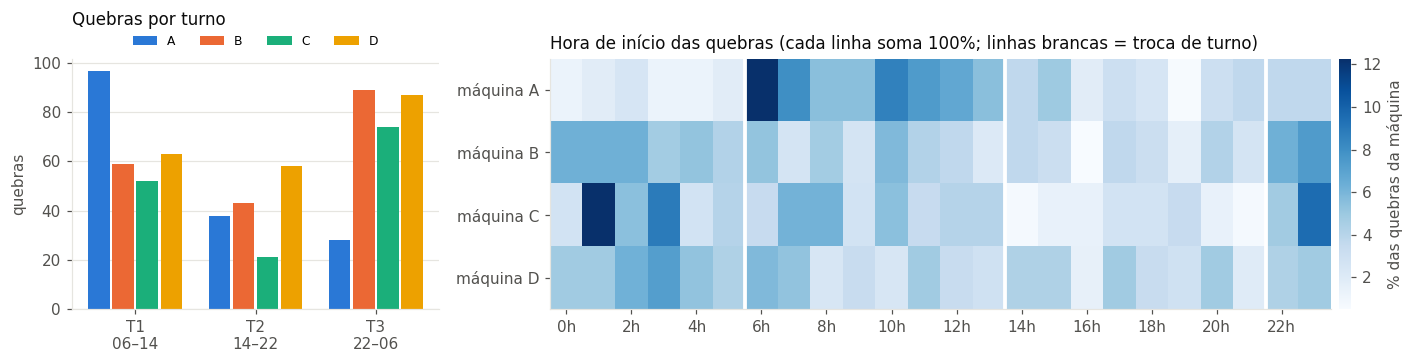

Quebras por turno (4 máquinas): {1: 271, 2: 160, 3: 278}  |  χ² = 37.1, p = 8.8e-09


quebras          horas               mediana_h          
turno         1   2   3      1      2      3         1    2    3
maquina                                                         
A            97  38  28 190.90  91.40 108.70      0.90 1.20 2.20
B            59  43  89  69.00  39.50  86.30      0.80 0.60 0.70
C            52  21  74 158.70  54.80 230.50      2.20 2.10 2.30
D            63  58  87 130.40 134.50 183.30      1.50 1.80 1.60

In [18]:
def turno_de(h):
    return np.select([(h >= 6) & (h < 14), (h >= 14) & (h < 22)], [1, 2], default=3)

quebras["hora"] = quebras["inicio"].dt.hour
quebras["turno"] = turno_de(quebras["hora"])
quebras["dia_semana"] = quebras["inicio"].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1, 2.2]})

# (a) quebras por turno, por máquina (contagem e horas)
ax = axes[0]
tt = quebras.pivot_table(index="turno", columns="maquina", values="duracao_h", aggfunc="size", fill_value=0)
x = np.arange(3); w = 0.2
for i, m in enumerate(MAQS):
    ax.bar(x + (i - 1.5) * w, tt[m], width=w - 0.02, color=COR_MAQ[m], label=m)
ax.set_xticks(x, ["T1\n06–14", "T2\n14–22", "T3\n22–06"]); ax.grid(axis="x", visible=False)
ax.set_ylabel("quebras"); ax.legend(frameon=False, ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Quebras por turno", pad=22)

# (b) perfil por hora do dia: % das quebras de cada máquina que começam em cada hora
ax = axes[1]
hw = (quebras.pivot_table(index="maquina", columns="hora", values="duracao_h", aggfunc="size", fill_value=0)
             .reindex(columns=range(24), fill_value=0))
hw = hw.div(hw.sum(axis=1), axis=0) * 100
im = ax.imshow(hw.values, cmap="Blues", aspect="auto")
ax.set_yticks(range(len(hw)), [f"máquina {m}" for m in hw.index])
ax.set_xticks(range(0, 24, 2), [f"{h}h" for h in range(0, 24, 2)]); ax.grid(False)
for xb in (5.5, 13.5, 21.5):
    ax.axvline(xb, color="white", lw=2.5)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("% das quebras da máquina"); cb.outline.set_visible(False)
ax.set_title("Hora de início das quebras (cada linha soma 100%; linhas brancas = troca de turno)")
fig.tight_layout(); salvar(fig, "18_padroes_temporais.png"); plt.show()

# teste qui-quadrado: as quebras se distribuem igualmente entre os turnos?
obs = quebras.groupby("turno").size()
chi2, p_turno = stats.chisquare(obs)
print(f"Quebras por turno (4 máquinas): {obs.to_dict()}  |  χ² = {chi2:.1f}, p = {p_turno:.2g}")
quebras.groupby(["maquina", "turno"]).agg(quebras=("id_parada", "size"), horas=("duracao_h", "sum"),
                                         mediana_h=("duracao_h", "median")).unstack("turno").round(1)

**Leitura dos resultados:**
- A divisão entre turnos **não é igual** (χ², p muito menor que 0,001: é praticamente impossível que seja sorte). Nas máquinas B–D, o turno 3 (noite) concentra mais quebras.
- **A máquina A é a exceção:** ≈ 60% das quebras começam no turno 1 (06–14), com pico na primeira hora do turno. Há duas hipóteses, que os dados sozinhos não separam:
  1. **operacional**: partida ou troca de produto no início do dia, condição de temperatura (o AQUECIMENTO é o maior ofensor);
  2. **de anotação**: no turno 1 a equipe de manutenção está presente e a parada é registrada como QUEBRA; à noite, o mesmo problema pode ser resolvido pelo operador e anotado como AJUSTE (a A tem a maior fração de horas em ajuste sem ordem SAP, seção 8.1).
- As quebras da A no turno 3 são **mais longas** (mediana ≈ 2,2 h contra ≈ 0,9 h no turno 1), o que combina com a hipótese 2: à noite só vira "quebra" o que o operador não resolve sozinho, e o atendimento demora mais. Uma conversa com os líderes de turno resolve a dúvida rapidamente, e o acionamento digital do Subproduto 1 elimina a ambiguidade na origem.

## 8. O que só aparece com MES e SAP juntos

### 8.1 Cobertura: quanto da perda da Produção tem registro da Manutenção?

Para cada parada do MES, verificamos se ela recebeu pelo menos uma ordem do SAP na conciliação (classe `MES + SAP`). É como conferir quantas idas ao pronto-socorro geraram um prontuário médico.

**Por que medir em horas e não em quantidade:** uma quebra de 5 h sem ordem é uma lacuna muito maior do que um ajuste de 5 min sem ordem. Contar só "quantas" trataria as duas como iguais.

As ligações de confiança **baixa** são contadas à parte, porque ainda dependem de conferência humana. Cada barra do gráfico mostra, para uma máquina e um tipo de parada, a fatia das horas com ordem de confiança alta/média, com ordem de confiança baixa e sem ordem.

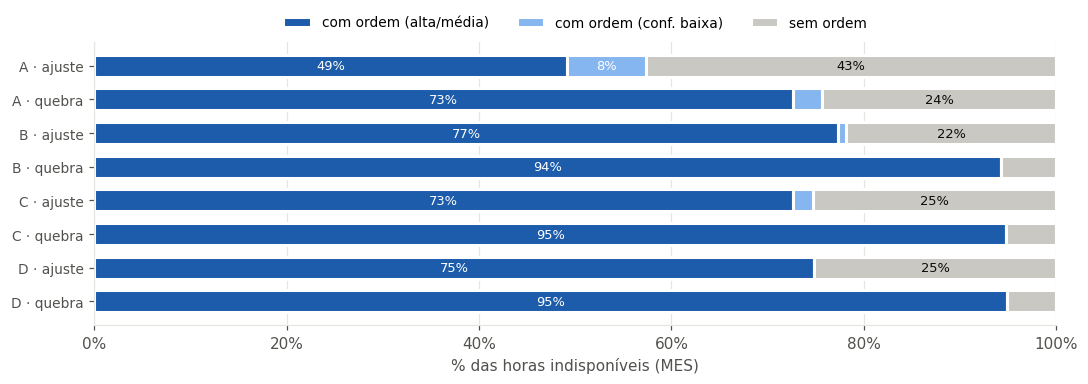

status               com ordem (alta/média)  com ordem (conf. baixa)  \
maquina tipo_parada                                                    
A       AJUSTE                        49.10                     8.20   
        QUEBRA                        72.60                     3.00   
B       AJUSTE                        77.30                     0.90   
        QUEBRA                        94.30                     0.00   
C       AJUSTE                        72.70                     2.00   
        QUEBRA                        94.80                     0.00   
D       AJUSTE                        74.90                     0.00   
        QUEBRA                        94.90                     0.00   

status               sem ordem  
maquina tipo_parada             
A       AJUSTE           42.70  
        QUEBRA           24.30  
B       AJUSTE           21.80  
        QUEBRA            5.70  
C       AJUSTE           25.30  
        QUEBRA            5.20  
D       AJUSTE           25.10  
        QUEBRA            5.10

In [19]:
cob = paradas.merge(eventos[["id_parada", "classe", "confianca"]], on="id_parada", how="left")
cob["status"] = np.where(cob["classe"] != "MES + SAP", "sem ordem",
                         np.where(cob["confianca"] == "baixa", "com ordem (conf. baixa)", "com ordem (alta/média)"))
tab_cob = (cob.pivot_table(index=["maquina", "tipo_parada"], columns="status", values="duracao_h",
                           aggfunc="sum", fill_value=0))
tab_cob = tab_cob[["com ordem (alta/média)", "com ordem (conf. baixa)", "sem ordem"]]
pct_cob = tab_cob.div(tab_cob.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
cores = [COR_CONF["alta"], COR_CONF["baixa"], NEUTRO]
rotulos = [f"{m} · {t.lower()}" for m, t in pct_cob.index]
esq = np.zeros(len(pct_cob))
for col, cor in zip(pct_cob.columns, cores):
    v = pct_cob[col].to_numpy()
    ax.barh(range(len(v)), v, left=esq, color=cor, height=0.65, edgecolor="white", linewidth=2, label=col)
    for i, (x0, wv) in enumerate(zip(esq, v)):
        if wv >= 8:
            ax.text(x0 + wv / 2, i, f"{wv:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if cor != NEUTRO else TXT)
    esq += v
ax.set_yticks(range(len(rotulos)), rotulos, fontsize=9); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter()); ax.grid(axis="y", visible=False)
ax.set_xlabel("% das horas indisponíveis (MES)")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
fig.tight_layout(); salvar(fig, "19_cobertura_sap.png"); plt.show()
pct_cob.round(1)

**Leitura dos resultados:** nas máquinas B–D, ≈ 95% das horas de quebra têm ordem no SAP; na **máquina A, ≈ 24% não têm**, e nos ajustes da A a lacuna chega a ≈ 43%. Em horas, são ≈ 95 h de quebra da A no semestre **sem nenhum registro da manutenção**. É a medida direta de "os sistemas contam histórias diferentes": um quarto da perda por quebra da máquina principal não tem descrição do que foi feito, e por isso nunca entra numa análise de falha.

### 8.2 Para onde vai o tempo de uma parada

Usando os eventos ligados com confiança **alta ou média** (e sem ordens de calendário longo), dividimos o tempo de cada parada em três pedaços, com a linha do tempo `t0 → t1 → t2 → t3` do notebook de conciliação (máquina para → começa o serviço → termina o serviço → máquina volta):

$$\underbrace{t_3 - t_0}_{\text{tempo parado (MES)}} = \underbrace{\text{espera}}_{\text{de } t_0 \text{ até a 1ª ordem começar}} + \underbrace{\text{atuação}}_{\text{ordens SAP dentro da parada}} + \underbrace{\text{restante}}_{\text{intervalos sem ordem e retomada}}$$

**Analogia do pronto-socorro:** **espera** é o tempo na sala de espera; **atuação** é o tempo com o médico; **restante** é todo o resto (esperar exame, esperar remédio, papelada da alta).

- **Espera** = $\min(\max(t_1 - t_0, 0),\ t_3 - t_0)$: tempo de parada antes de a manutenção registrar o início. A fórmula só garante que a espera nunca é negativa nem maior que a própria parada. É uma **aproximação** do tempo de resposta pedido no case (o instante do chamado não existe na base).
- **Atuação** = tempo das ordens do SAP (somado sem repetir trechos sobrepostos), cortado para caber dentro da parada (`atuacao_na_parada_h`).
- **Restante** = o que sobra: espera entre uma ordem e outra, teste, liberação e retomada da produção.

Na máquina A os horários do SAP são arredondados e às vezes começam antes da parada; por isso a espera pode sair menor do que a real. A comparação entre máquinas vale como ordem de grandeza.

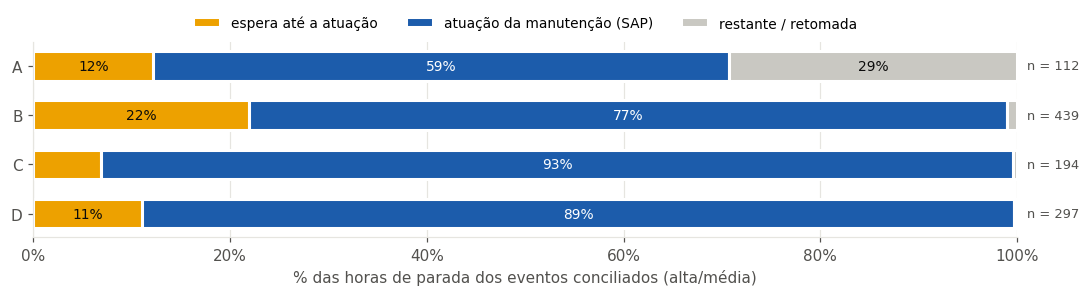

,eventos,espera_mediana_min,atuacao_mediana_min,indisp_mediana_min
maquina,,,,
A,112,0.00,84.00,132.00
B,439,8.00,17.00,25.00
C,194,10.00,85.00,98.00
D,297,10.00,51.00,65.00


In [20]:
cf = eventos[(eventos["classe"] == "MES + SAP") & eventos["confianca"].isin(["alta", "media"])
             & ~eventos["ordem_longa"].astype(bool)].copy()
cf["espera_h"] = (cf["espera_ate_atuacao_min"] / 60).clip(lower=0)
cf["espera_h"] = np.minimum(cf["espera_h"], cf["indisponibilidade_h"])
cf["atuacao_h_in"] = np.minimum(cf["atuacao_na_parada_h"], cf["indisponibilidade_h"] - cf["espera_h"])
cf["restante_h"] = (cf["indisponibilidade_h"] - cf["espera_h"] - cf["atuacao_h_in"]).clip(lower=0)

dec = cf.groupby("maquina")[["espera_h", "atuacao_h_in", "restante_h"]].sum()
dec_pct = dec.div(dec.sum(axis=1), axis=0) * 100
med = cf.groupby("maquina").agg(eventos=("id_evento", "size"),
                                espera_mediana_min=("espera_h", lambda s: s.median() * 60),
                                atuacao_mediana_min=("atuacao_h_in", lambda s: s.median() * 60),
                                indisp_mediana_min=("indisponibilidade_h", lambda s: s.median() * 60))

fig, ax = plt.subplots(figsize=(10, 2.8))
cores = {"espera_h": "#eda100", "atuacao_h_in": COR_CONF["alta"], "restante_h": NEUTRO}
nomes = {"espera_h": "espera até a atuação", "atuacao_h_in": "atuação da manutenção (SAP)", "restante_h": "restante / retomada"}
esq = np.zeros(len(dec_pct))
for col in dec_pct.columns:
    v = dec_pct[col].to_numpy()
    ax.barh(dec_pct.index, v, left=esq, color=cores[col], height=0.6, edgecolor="white", linewidth=2, label=nomes[col])
    for i, (x0, wv) in enumerate(zip(esq, v)):
        if wv >= 7:
            ax.text(x0 + wv / 2, i, f"{wv:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if col == "atuacao_h_in" else TXT)
    esq += v
for i, m in enumerate(dec_pct.index):
    ax.text(101, i, f"n = {med.loc[m, 'eventos']:.0f}", va="center", fontsize=8.5, color=TXT2)
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("% das horas de parada dos eventos conciliados (alta/média)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
fig.tight_layout(); salvar(fig, "20_decomposicao_parada.png"); plt.show()
med.round(0)

**Leitura dos resultados:**
- Nas máquinas B–D, a ordem do SAP cobre quase toda a parada (77–93%), e a espera mediana até o início do serviço é de ≈ 8–10 min: o SAP e o MES contam a mesma história com um pequeno atraso.
- Na **máquina A, ≈ 29% das horas de parada ficam fora de qualquer ordem** ("restante"): a máquina está parada, mas não há serviço registrado. Esse tempo pode ser espera por peça, por pessoa, teste, liberação, ou serviço não anotado; os dados não dizem qual. É o tempo que o acionamento digital do Subproduto 1, com etapas de status (aberto → em atendimento → aguardando peça → liberado), tornaria visível.
- A espera mediana da A sai **0 min** porque, em boa parte dos eventos, o SAP registra o início **antes** da parada (horários arredondados, anotação feita depois). Não significa que a resposta é instantânea; significa que o horário do SAP da A não serve para medir tempo de resposta. É mais um argumento para registrar o chamado na origem.

### 8.3 Os números que "nunca fecham"

Quantas horas cada sistema atribui à mesma máquina no semestre. A diferença **não é erro** de um dos lados: os sistemas medem coisas diferentes. A Produção mede **a máquina parada**; a Manutenção mede **a ordem aberta**, que pode incluir trabalho com a máquina funcionando e ordens que ficaram abertas por dias.

É como comparar o tempo que o carro ficou fora de uso com o tempo que a oficina diz que trabalhou nele: se a oficina deixou a ficha aberta no fim de semana, os números não batem, e ninguém mentiu.

A conciliação separa a parte **comparável** (eventos `MES + SAP`) do que é exclusivo de cada lado. No gráfico, para cada máquina, a barra de cima é o MES e a de baixo é o SAP, cada uma dividida em "com par" e "sem par".

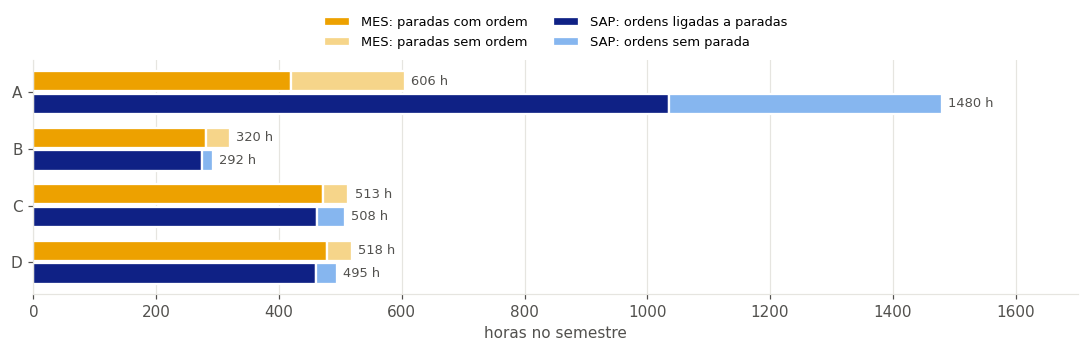

,MES: paradas com ordem,MES: paradas sem ordem,SAP: ordens ligadas a paradas,SAP: ordens sem parada,total MES,total SAP,SAP ÷ MES,ordens_longas,horas_longas,SAP ÷ MES sem longas
maquina,,,,,,,,,,
A,418.93,186.75,"1,035.95",443.76,605.68,"1,479.71",2.44,9.00,605.03,1.44
B,281.25,38.38,274.24,17.72,319.62,291.97,0.91,0.00,0.00,0.91
C,472.48,40.60,461.65,45.99,513.09,507.64,0.99,0.00,0.00,0.99
D,477.59,40.65,460.16,34.62,518.24,494.78,0.95,0.00,0.00,0.95


In [21]:
h_mes = eventos.groupby(["maquina", "classe"])["indisponibilidade_h"].sum().unstack(fill_value=0)
h_sap = eventos.groupby(["maquina", "classe"])["atuacao_h"].sum().unstack(fill_value=0)
fecha = pd.DataFrame({
    "MES: paradas com ordem": h_mes["MES + SAP"],
    "MES: paradas sem ordem": h_mes["MES sem SAP"],
    "SAP: ordens ligadas a paradas": h_sap["MES + SAP"],
    "SAP: ordens sem parada": h_sap["SAP sem MES"],
})
fecha["total MES"] = fecha.iloc[:, 0] + fecha.iloc[:, 1]
fecha["total SAP"] = fecha.iloc[:, 2] + fecha.iloc[:, 3]
fecha["SAP ÷ MES"] = fecha["total SAP"] / fecha["total MES"]

fig, ax = plt.subplots(figsize=(10, 3.3))
y = np.arange(len(MAQS)); hgt = 0.36
for off, cols, cs in [(-hgt / 2 - 0.02, ["MES: paradas com ordem", "MES: paradas sem ordem"], ["#eda100", "#f6d58a"]),
                      (hgt / 2 + 0.02, ["SAP: ordens ligadas a paradas", "SAP: ordens sem parada"], ["#0f2185", "#86b6ef"])]:
    esq = np.zeros(len(MAQS))
    for c, cor in zip(cols, cs):
        v = fecha.loc[MAQS, c].to_numpy()
        ax.barh(y + off, v, left=esq, height=hgt, color=cor, edgecolor="white", linewidth=1.5, label=c)
        esq += v
    for yi, tot in zip(y + off, esq):
        ax.text(tot + 10, yi, f"{tot:.0f} h", va="center", fontsize=8.5, color=TXT2)
ax.set_yticks(y, MAQS); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("horas no semestre"); ax.set_xlim(0, fecha[["total MES", "total SAP"]].max().max() * 1.15)
ax.legend(frameon=False, ncol=2, fontsize=8.5, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); salvar(fig, "21_mes_x_sap_horas.png"); plt.show()

# quanto da diferença vem de ordens de calendário longo (> 24 h)?
longas = vinculo[vinculo["ordem_longa"].astype(bool)].groupby("maquina").agg(ordens_longas=("n_ordem", "size"),
                                                                           horas_longas=("horas", "sum"))
fecha = fecha.join(longas).fillna({"ordens_longas": 0, "horas_longas": 0})
fecha["SAP ÷ MES sem longas"] = (fecha["total SAP"] - fecha["horas_longas"]) / fecha["total MES"]
fecha.round(2)

**Leitura dos resultados:** em B, C e D os dois sistemas fecham com diferença de até 10%. Na **máquina A, o SAP registra ≈ 2,4× as horas do MES**. A maior parte da diferença vem de **9 ordens de calendário longo (mais de 24 h) que somam ≈ 605 h**, praticamente o mesmo que toda a indisponibilidade da A no MES. Sem elas, a razão cai para ≈ 1,4×. Ou seja: a "discussão sobre qual número é o verdadeiro" na A é causada, em grande parte, por um punhado de ordens deixadas abertas, e não por uma divergência sistemática. Fechar as ordens no fim do atendimento (ou separar tempo de serviço de tempo de calendário na anotação) resolve a maior parte do problema.

### 8.4 Primeira leitura do texto do SAP: o que quebra e como (máquina A)

Antes da classificação completa do Subproduto 3, uma lista simples de regras de busca extrai três informações do texto curto de cada ordem:

- **objeto**: o código de componente do MES citado no texto (a lista de códigos é tirada da própria base: qualquer código de componente que aparece no MES da máquina) ou um nome genérico de peça (LONA, ROLO, MOTOR, BOMBA...);
- **modo de falha**: a primeira expressão reconhecida (TRAVADO, NÃO LIGA, VAZAMENTO, DANIFICADO, DESALINHADO...);
- **genérico**: textos que só dizem "falha", "problema" ou o nome da peça, sem dizer **como** falhou. São os registros que o case descreve como "o texto livre que deveria explicar a falha não explica nada".

**Como funcionam as regras:** são **padrões de busca** (em programação, "expressões regulares"), como um "Ctrl+F" turbinado. Por exemplo, o padrão `TRAVAD` encontra "TRAVADO", "TRAVADA" e "TRAVADOS" de uma vez. A lista de modos é verificada em ordem, e o primeiro que aparecer no texto vence.

🔧 **Por que algo tão simples:** é deliberadamente transparente (qualquer pessoa entende por que uma ordem caiu em cada categoria). Serve para **medir o tamanho do problema de qualidade do texto** e dar uma primeira tabela componente × modo de falha, não para substituir o Subproduto 3.

Máquina A: 521 ordens | modo de falha identificado em 39% | objeto identificado em 78% | texto pobre (falta modo ou objeto): 69%


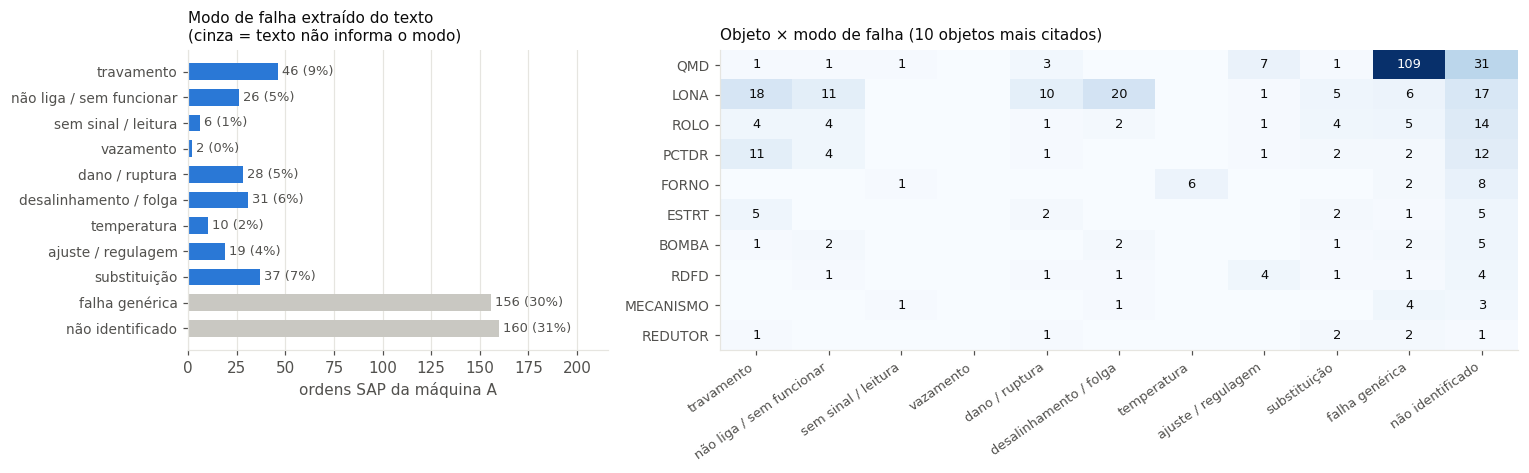

In [22]:
MODOS = [
    ("travamento", r"\bTRAVAD|\bPRES[AO]\b|\bAGARR|\bENGASG|\bENTUP|\bOBSTRU"),
    ("não liga / sem funcionar", r"NAO LIGA|SEM FUNCION|NAO FUNCION|SEM ACION|NAO ACION|DESLIG|PAROU|SEM MOVIMENTO"),
    ("sem sinal / leitura", r"SEM SINAL|SINAL|LEITURA|ENCODER|SENSOR"),
    ("vazamento", r"VAZ"),
    ("dano / ruptura", r"DANIFIC|QUEBRAD|ROMPID|TRINC|DESGAST|FURAD|QUEIMAD|CURTO"),
    ("desalinhamento / folga", r"DESALIN|FOLGA|SOLT|FROUX|RETRAC"),
    ("temperatura", r"AQUEC|TEMPERATURA|SUPERAQ"),
    ("ajuste / regulagem", r"\bAJUST|\bREGUL|\bALINHA|\bCALIBR|\bREAPERT|\bTENSION"),
    ("substituição", r"SUBSTIT|\bTROCA|\bTROCAR|MONTAGEM|\bINSTAL"),
    ("falha genérica", r"\bFALHA|\bPROBLEMA|\bVERIFICAR|\bDEFEITO|\bMANUTENCAO"),
]
PECAS = ["LONA", "ROLO", "MOTOR", "BOMBA", "REDUTOR", "CORREIA", "EIXO", "MECANISMO", "FORNO", "CILINDRO", "MANCAL", "ROLAMENTO"]

def classificar_texto(texto, codigos):
    t = str(texto) if pd.notna(texto) else ""
    toks = re.split(r"[^A-Z0-9]+", t)
    obj = next((tk for tk in toks if tk in codigos), None)
    if obj is None:
        obj = next((p for p in PECAS for tk in toks if tk.startswith(p)), "não identificado")
    modo = next((nome for nome, rx in MODOS if re.search(rx, t)), "não identificado")
    return obj, modo

sA = sap[sap["valido"] & (sap["maquina"] == "A")].copy()
codigos_A = set(mes.loc[mes["maquina"] == "A", "componente"].dropna().unique())
sA[["objeto", "modo"]] = sA["texto_padronizado"].apply(lambda t: pd.Series(classificar_texto(t, codigos_A)))
sA["texto_pobre"] = sA["modo"].isin(["falha genérica", "não identificado"]) | (sA["objeto"] == "não identificado")

print(f"Máquina A: {len(sA)} ordens | modo de falha identificado em {(~sA['modo'].isin(['falha genérica', 'não identificado'])).mean() * 100:.0f}% "
      f"| objeto identificado em {(sA['objeto'] != 'não identificado').mean() * 100:.0f}% "
      f"| texto pobre (falta modo ou objeto): {sA['texto_pobre'].mean() * 100:.0f}%")

top_obj = sA["objeto"].value_counts().drop("não identificado", errors="ignore").head(10).index
ordem_modo = [n for n, _ in MODOS] + ["não identificado"]
mat = (pd.crosstab(sA.loc[sA["objeto"].isin(top_obj), "objeto"], sA.loc[sA["objeto"].isin(top_obj), "modo"])
         .reindex(index=top_obj, columns=[m for m in ordem_modo if m in sA["modo"].unique()], fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.9]})
ax = axes[0]
vc = sA["modo"].value_counts().reindex(ordem_modo).dropna()
cores_m = [NEUTRO if m in ("falha genérica", "não identificado") else COR_MAQ["A"] for m in vc.index]
ax.barh(range(len(vc)), vc.values, color=cores_m, height=0.65)
for i, v in enumerate(vc.values):
    ax.text(v + 2, i, f"{v:.0f} ({v / len(sA) * 100:.0f}%)", va="center", fontsize=8.5, color=TXT2)
ax.set_yticks(range(len(vc)), vc.index, fontsize=9); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, vc.max() * 1.35); ax.set_xlabel("ordens SAP da máquina A")
ax.set_title("Modo de falha extraído do texto\n(cinza = texto não informa o modo)", fontsize=10)

ax = axes[1]
im = ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=35, ha="right", fontsize=8.5)
ax.set_yticks(range(mat.shape[0]), mat.index, fontsize=9); ax.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8.5, color="white" if v > mat.values.max() * 0.55 else TXT)
ax.set_title("Objeto × modo de falha (10 objetos mais citados)", fontsize=10)
fig.tight_layout(); salvar(fig, "22_texto_sap_modo_falha_A.png"); plt.show()

**Como ler a figura:** à esquerda, quantas ordens caíram em cada modo de falha (em cinza, as que **não dizem** como falharam). À direita, um mapa de calor cruzando os 10 objetos mais citados com os modos de falha: cada célula é o número de ordens daquele objeto com aquele modo.

**Leitura dos resultados:**
- **61% das ordens da máquina A não dizem como o equipamento falhou** (30% só dizem "falha"/"problema"/"verificar"; 31% nem isso). Somando os casos em que nem o objeto é identificado, ≈ 69% dos textos não têm informação suficiente para uma análise de falha.
- O caso mais claro é o **QMD**: é o objeto mais citado (≈ 150 ordens), e em ≈ 109 delas o texto é só uma variação de "QMD em falha" / "falha nos QMD". O componente que mais aparece no SAP é justamente o que menos se explica.
- **LONA** é o oposto: tem modos de falha descritos (desalinhamento/retração, travamento, não liga, dano). É o tipo de registro que permite agrupar falhas pela causa.
- Para o Subproduto 3, isso define o alvo: uma lista fechada de modos de falha por objeto (a tabela acima é um ponto de partida) e um campo obrigatório na anotação quando o texto cair em "falha genérica".

## 9. As intervenções planejadas reduzem quebras posteriores?

**O que os dados permitem e o que não permitem.** O case pede para avaliar o efeito das manutenções **preventivas**. A base do SAP, porém, só traz ordens `CORRETIVA` e `CORRETIVA PLANEJADA` (tabela abaixo): não há ordens preventivas para comparar com as falhas seguintes. Essa ausência já é um achado: sem o histórico de preventivas (plano, periodicidade, execução), a efetividade do plano não pode ser medida, só estimada por um **proxy** (uma medida "substituta", que aproxima a pergunta original).

**O proxy usado:** comparar o que acontece **depois** de uma quebra atendida por ordem *corretiva* (emergencial, "apaga incêndio") com uma atendida por ordem *corretiva planejada* (programada). Para cada quebra ligada ao SAP, medimos o tempo até a **próxima quebra do mesmo equipamento**. Se a intervenção planejada for mais efetiva, o equipamento deve demorar mais para quebrar de novo.

### O problema das histórias "sem final" e a curva de Kaplan–Meier

Algumas quebras **não têm "próxima" quebra** dentro do semestre: o equipamento foi consertado e ainda não quebrou de novo quando os dados acabaram. Não sabemos quanto tempo ele vai durar; sabemos só que durou **pelo menos** até o fim da base. Isso se chama observação **censurada**.

**Analogia:** é como medir quanto tempo as pessoas ficam num emprego, olhando só os últimos 6 meses. Quem ainda está empregado não "saiu", mas também não podemos dizer que fica para sempre. Jogar essas pessoas fora faria parecer que todos saem rápido (só sobraria quem já saiu); tratá-las como se tivessem saído no último dia também erraria.

O **estimador de Kaplan–Meier** resolve isso: ele calcula, dia a dia, a **porcentagem de equipamentos que ainda não quebraram de novo**, em que cada equipamento censurado conta como "ainda sem quebrar" durante todo o tempo em que foi observado e, depois disso, simplesmente sai da conta, sem ser tratado nem como quebra nem como sobrevivente eterno. O resultado é uma "escada" que começa em 100% e vai descendo (a **curva de sobrevivência**).

**Para comparar as duas curvas** usamos o **teste log-rank**: ele pergunta "a diferença entre as duas escadas é maior do que o acaso explicaria?", comparando, a cada dia, quantas quebras aconteceram em cada grupo com quantas seriam esperadas se os dois grupos fossem iguais. O resultado é um p-valor (p < 0,05 = diferença real).

Ordens SAP válidas por tipo:


maquina,A,B,C,D,Total
tipo,,,,,
CORRETIVA,110,111,95,134,450
CORRETIVA PLANEJADA,411,366,121,199,1097
Total,521,477,216,333,1547


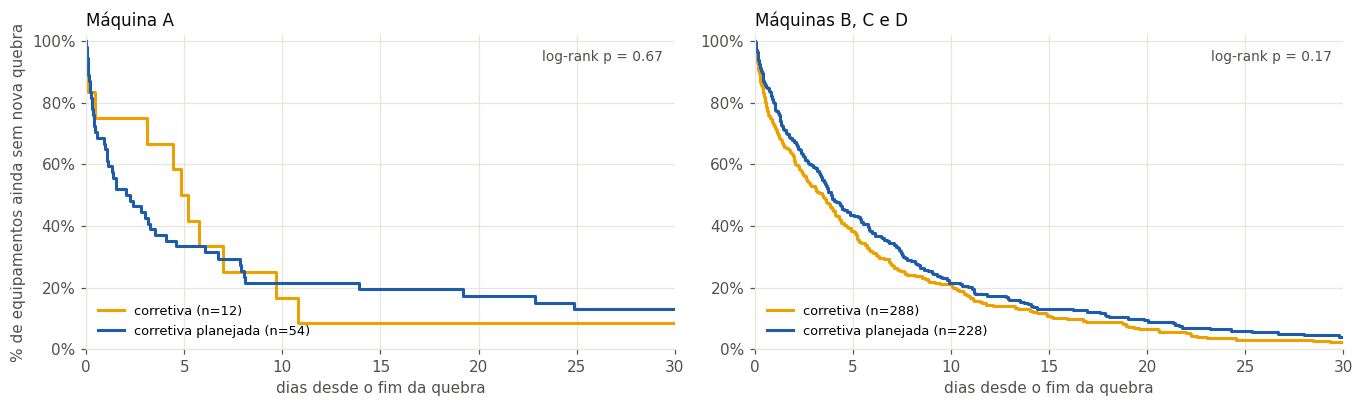

,grupo,tipo,n,mediana_dias_ate_prox,%_sem_nova_quebra_em_7d,p_logrank
0,Máquina A,CORRETIVA,12,4.90,24.90,0.70
1,Máquina A,CORRETIVA PLANEJADA,54,2.20,28.90,0.70
2,"Máquinas B, C e D",CORRETIVA,288,3.40,27.00,0.20
3,"Máquinas B, C e D",CORRETIVA PLANEJADA,228,3.90,34.30,0.20


In [23]:
print("Ordens SAP válidas por tipo:")
display(pd.crosstab(sap.loc[sap["valido"], "tipo"], sap.loc[sap["valido"], "maquina"], margins=True, margins_name="Total"))

q_eq = quebras.sort_values(["maquina", "equipamento", "inicio"]).copy()
q_eq["prox_inicio"] = q_eq.groupby(["maquina", "equipamento"])["inicio"].shift(-1)
q_eq["evento"] = q_eq["prox_inicio"].notna()
q_eq["dias_ate_prox"] = np.where(q_eq["evento"],
                                 (q_eq["prox_inicio"] - q_eq["fim"]).dt.total_seconds() / 86400,
                                 (T_FIM - q_eq["fim"]).dt.total_seconds() / 86400)
sv = q_eq[(q_eq["classe"] == "MES + SAP") & q_eq["confianca"].isin(["alta", "media"])].copy()

def kaplan_meier(t, e):
    """Estimador de Kaplan–Meier. Retorna tempos e S(t) em degrau."""
    d = pd.DataFrame({"t": t, "e": e.astype(int)}).sort_values("t")
    tab = d.groupby("t")["e"].agg(["sum", "size"])
    n_risco = len(d) - tab["size"].cumsum().shift(fill_value=0)
    s = (1 - tab["sum"] / n_risco).cumprod()
    return np.r_[0, s.index.to_numpy()], np.r_[1, s.to_numpy()]

def logrank(t1, e1, t2, e2):
    t = np.r_[t1, t2]; e = np.r_[e1, e2].astype(int); g = np.r_[np.zeros(len(t1)), np.ones(len(t2))]
    O = E = V = 0.0
    for ti in np.unique(t[e == 1]):
        risco = t >= ti
        n, n1 = risco.sum(), (risco & (g == 0)).sum()
        d = ((t == ti) & (e == 1)).sum(); d1 = ((t == ti) & (e == 1) & (g == 0)).sum()
        O += d1; E += d * n1 / n
        V += d * (n1 / n) * (1 - n1 / n) * (n - d) / (n - 1) if n > 1 else 0
    chi = (O - E) ** 2 / V if V else np.nan
    return chi, stats.chi2.sf(chi, 1)

def mediana_km(tt, s):
    abaixo = np.where(s <= 0.5)[0]
    return tt[abaixo[0]] if len(abaixo) else np.nan

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
res_km = []
for ax, (titulo, sel) in zip(axes, [("Máquina A", sv["maquina"] == "A"), ("Máquinas B, C e D", sv["maquina"] != "A")]):
    g = sv[sel]
    grupos = {}
    for tipo, cor in [("CORRETIVA", "#eda100"), ("CORRETIVA PLANEJADA", COR_CONF["alta"])]:
        gg = g[g["tipo_sap"] == tipo]
        if len(gg) < 5:
            continue
        tt, s = kaplan_meier(gg["dias_ate_prox"].to_numpy(), gg["evento"].to_numpy())
        ax.step(tt, s * 100, where="post", lw=2, color=cor, label=f"{tipo.lower()} (n={len(gg)})")
        grupos[tipo] = gg
        res_km.append({"grupo": titulo, "tipo": tipo, "n": len(gg), "mediana_dias_ate_prox": mediana_km(tt, s),
                       "%_sem_nova_quebra_em_7d": np.interp(7, tt, s) * 100})
    if len(grupos) == 2:
        a, b = grupos.values()
        chi, p = logrank(a["dias_ate_prox"].to_numpy(), a["evento"].to_numpy(),
                         b["dias_ate_prox"].to_numpy(), b["evento"].to_numpy())
        ax.text(0.98, 0.95, f"log-rank p = {p:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=9, color=TXT2)
        for linha in res_km[-2:]:
            linha["p_logrank"] = p
    ax.set_xlim(0, 30); ax.set_ylim(0, 102); ax.yaxis.set_major_formatter(PercentFormatter())
    ax.set_xlabel("dias desde o fim da quebra"); ax.set_title(titulo)
    ax.legend(frameon=False, fontsize=8.5, loc="lower left")
axes[0].set_ylabel("% de equipamentos ainda sem nova quebra")
fig.tight_layout(); salvar(fig, "23_efetividade_intervencoes.png"); plt.show()
pd.DataFrame(res_km).round(1)

**Leitura dos resultados:** em nenhum dos dois grupos há diferença significativa entre as curvas (log-rank p ≈ 0,67 na A e ≈ 0,17 em B–D; a tabela mostra esses valores arredondados para 0,7 e 0,2). Nas máquinas B–D a curva da planejada fica levemente acima (o equipamento demora um pouco mais para quebrar de novo), mas a diferença está dentro do que o acaso explica. Na A, a comparação tem só 12 eventos corretivos ligados com confiança alta/média, pouco para qualquer conclusão. Em todos os casos, **entre 2/3 e 3/4 dos equipamentos quebram de novo em até uma semana**, qualquer que seja o tipo de intervenção, o que reforça o achado de reincidência da seção 5.

**Cuidados na leitura (viés de seleção).** A ordem "planejada" não é sorteada: ela costuma ser aberta para problemas que **podiam esperar**, enquanto a corretiva atende a falha grave. Os dois grupos já começam diferentes. 💡 É como comparar a recuperação de pacientes de consulta marcada com a de pacientes de pronto-socorro: a diferença pode vir da gravidade do caso, e não do tipo de atendimento. Por isso uma diferença entre as curvas seria **indício**, não prova de causa e efeito.

Para avaliar preventivas de verdade seriam necessários: (1) o histórico de ordens preventivas com plano e data de execução; (2) o componente / modo de falha padronizado (Subproduto 3), para comparar a falha *que a preventiva deveria evitar*; (3) idealmente, medições de condição (vibração, temperatura) antes e depois.

## 10. Ranking de priorização

Pergunta do case: *"se a Engenharia puder atacar apenas alguns problemas neste período, quais deveriam ser priorizados e por quê?"*

**Unidade:** equipamento de cada máquina (o nível em que um plano de ação é atribuído a alguém). Nenhum critério sozinho conta a história inteira (o que mais para não é necessariamente o que mais quebra, nem o que está piorando), então combinamos cinco critérios, todos calculados nas seções anteriores:

| Critério | Medida | Peso | Por que entra |
|---|---|---|---|
| Impacto | horas de quebra no semestre | 0,30 | é a perda de produção direta |
| Frequência | número de quebras | 0,20 | cada quebra é uma intervenção sob pressão (risco de segurança) e uma perturbação na qualidade |
| Reincidência | % das quebras em que o mesmo componente volta em até 30 dias | 0,20 | sinal de que a causa raiz não foi tratada; é onde a Engenharia mais agrega |
| Tendência | $U$ do teste de Laplace (seção 6) | 0,15 | antecipa o problema que vai crescer |
| Severidade | mediana do tempo de reparo | 0,15 | quebra longa costuma ser difícil de diagnosticar ou depender de peça |


### Como colocar critérios tão diferentes na mesma régua

Horas, contagens e porcentagens não podem ser somadas diretamente (seria somar "metros com quilos"). A solução é a **normalização por posto percentil**: para cada critério, ordenamos os equipamentos e trocamos o valor pela **posição relativa na fila**, de 0 a 1: o equipamento com o **maior** valor no critério (mais horas, mais quebras, mais reincidência...) fica perto de 1, e o de menor valor fica perto de 0. Quanto mais perto de 1, mais o equipamento "precisa de atenção" naquele critério.

É como a "classificação" num concurso: o que importa é a sua posição entre os candidatos, não a nota bruta. Vantagem: um valor extremo (um equipamento com 200 h quando os outros têm 20 h) não domina o resultado sozinho. O score final é a soma ponderada das posições.

### Os pesos são uma escolha: o ranking aguenta outra escolha?

**Os pesos são uma proposta, não um dado.** Para testar o quanto o resultado depende deles, sorteamos **5.000 conjuntos de pesos** parecidos com a proposta e refazemos o ranking em cada um. Os sorteios usam a **distribuição de Dirichlet**, que é uma "máquina de sortear pesos" que sempre produz pesos positivos que **somam 1** e ficam **ao redor** dos pesos propostos (com concentração 20, variações típicas de ±0,1).

**Analogia:** é como pedir a 5.000 engenheiros, cada um com uma opinião um pouco diferente sobre o que importa mais, que montem o ranking. Um equipamento que fica entre os 5 primeiros para quase todos eles é prioridade **independentemente** da discussão sobre pesos.

In [24]:
r_eq = r.groupby(["maquina", "equipamento"]).agg(q_comp=("id_registro", "size"), r30=("reinc_30d", "sum"))
crit = quebras.groupby(["maquina", "equipamento"]).agg(horas=("duracao_h", "sum"), quebras=("id_parada", "size"),
                                                      mediana_reparo_h=("duracao_h", "median"))
crit["reincidencia_%"] = (r_eq["r30"] / r_eq["q_comp"] * 100).reindex(crit.index).fillna(0)
crit["U_laplace"] = crit.index.map(lambda ix: laplace_U(
    (quebras.loc[(quebras["maquina"] == ix[0]) & (quebras["equipamento"] == ix[1]), "inicio"] - T_INI)
    .dt.total_seconds().to_numpy() / 3600, T_H))
crit = crit[crit["quebras"] >= 3]
crit["U_laplace"] = crit["U_laplace"].fillna(0)

PESOS = {"horas": 0.30, "quebras": 0.20, "reincidencia_%": 0.20, "U_laplace": 0.15, "mediana_reparo_h": 0.15}
postos = crit[list(PESOS)].rank(pct=True)
contrib = postos * pd.Series(PESOS)
crit["score"] = contrib.sum(axis=1)
crit = crit.sort_values("score", ascending=False)
contrib = contrib.loc[crit.index]

# robustez aos pesos
rng = np.random.default_rng(42)
W = rng.dirichlet(np.array(list(PESOS.values())) * 20, size=5000)        # concentração 20: variações de ±~0,1
sc = postos.loc[crit.index].to_numpy() @ W.T
top5 = (np.argsort(-sc, axis=0)[:5])
crit["%_no_top5"] = pd.Series(np.bincount(top5.ravel(), minlength=len(crit)) / W.shape[0] * 100, index=crit.index)
crit["posicao_mediana"] = np.median(np.argsort(np.argsort(-sc, axis=0), axis=0) + 1, axis=1)

print(f"{len(crit)} equipamentos avaliados (≥ 3 quebras)")
crit.head(12).round(2)

27 equipamentos avaliados (≥ 3 quebras)


horas  quebras  mediana_reparo_h  reincidencia_%  \
maquina equipamento                                                       
D       TRANSPORTADOR 141.27       55              1.97           88.14   
        DOSADOR       126.04       53              1.66           85.19   
C       REFRIGERACAO  106.83       37              2.03           76.92   
        TRANSMISSAO   105.77       33              2.26           78.79   
A       AQUECIMENTO   197.30       68              1.33           73.97   
B       ALIMENTADOR    48.16       53              0.63           77.36   
C       TRACIONADOR    86.21       31              2.43           70.97   
A       ROLOS         100.57       59              0.70           83.05   
B       PRENSA         51.25       47              0.74           74.47   
C       POSICIONADOR   47.25       14              2.69           50.00   
D       ROSCA SEM FIM  35.50       20              1.45           55.00   
        VIBRADOR       36.28       18              1.30           72.22   

                       U_laplace  score  %_no_top5  posicao_mediana  
maquina equipamento                                                  
D       TRANSPORTADOR       5.34   0.94     100.00             1.00  
        DOSADOR             5.07   0.88     100.00             2.00  
C       REFRIGERACAO        1.87   0.82      99.80             3.00  
        TRANSMISSAO         1.16   0.79      96.14             4.00  
A       AQUECIMENTO         0.78   0.78      90.92             5.00  
B       ALIMENTADOR         1.63   0.68       4.50             7.00  
C       TRACIONADOR         0.34   0.68       5.38             7.00  
A       ROLOS              -1.54   0.66       2.62             7.00  
B       PRENSA              0.04   0.60       0.00             9.00  
C       POSICIONADOR        1.29   0.58       0.54            10.00  
D       ROSCA SEM FIM       1.66   0.56       0.00            11.00  
        VIBRADOR            1.21   0.55       0.00            12.00

**Como ler a figura abaixo:** à esquerda, cada barra é o score de um equipamento, dividida em fatias coloridas que mostram **quanto cada critério contribuiu** (como uma nota final separada por prova). À direita, a porcentagem dos 5.000 sorteios de pesos em que o equipamento ficou entre os 5 primeiros. Barras escuras (≥ 80%) são as prioridades "à prova de discussão sobre pesos".

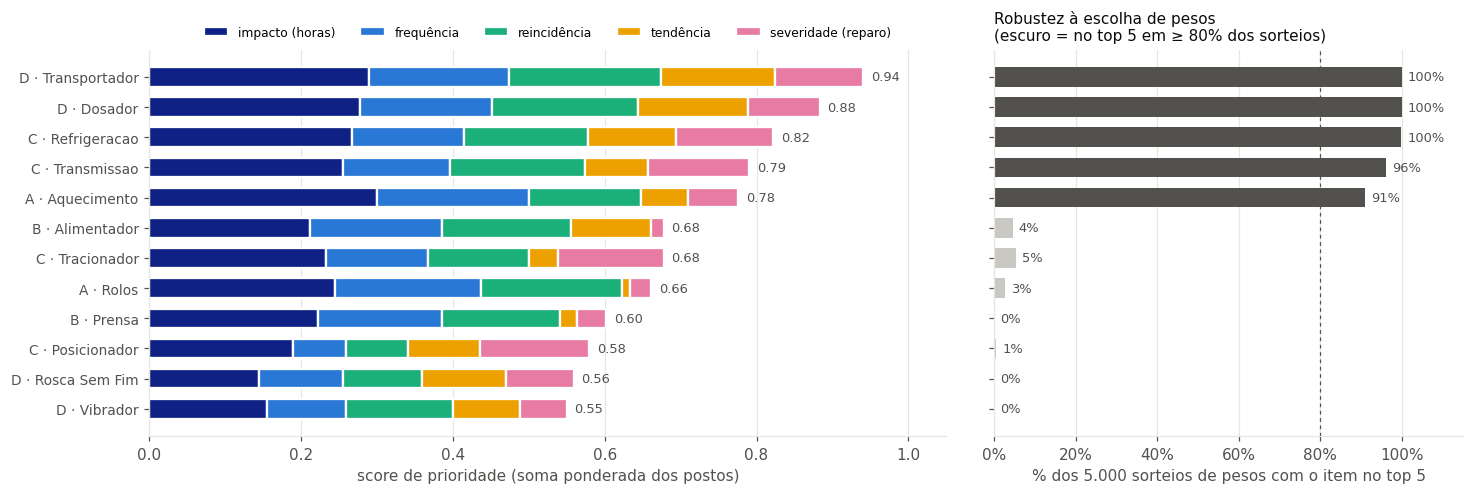

In [25]:
top = crit.head(12)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.7, 1]}, sharey=True)
ax = axes[0]
rot = [f"{m} · {e.title()}" for m, e in top.index]
nomes_c = {"horas": "impacto (horas)", "quebras": "frequência", "reincidencia_%": "reincidência",
           "U_laplace": "tendência", "mediana_reparo_h": "severidade (reparo)"}
cores_c = ["#0f2185", "#2a78d6", "#1baf7a", "#eda100", "#e87ba4"]
esq = np.zeros(len(top))
for (c, cor) in zip(PESOS, cores_c):
    v = contrib.loc[top.index, c].to_numpy()
    ax.barh(range(len(top)), v, left=esq, color=cor, height=0.65, edgecolor="white", linewidth=1.5, label=nomes_c[c])
    esq += v
for i, (s_, m) in enumerate(zip(top["score"], [ix[0] for ix in top.index])):
    ax.text(s_ + 0.01, i, f"{s_:.2f}", va="center", fontsize=8.5, color=TXT2)
ax.set_yticks(range(len(top)), rot, fontsize=9); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1.05); ax.set_xlabel("score de prioridade (soma ponderada dos postos)")
ax.legend(frameon=False, ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))

ax = axes[1]
ax.barh(range(len(top)), top["%_no_top5"], color=[TXT2 if v >= 80 else NEUTRO for v in top["%_no_top5"]], height=0.65)
for i, v in enumerate(top["%_no_top5"]):
    ax.text(v + 1.5, i, f"{v:.0f}%", va="center", fontsize=8.5, color=TXT2)
ax.axvline(80, color=TXT2, lw=0.8, ls=(0, (3, 3)))
ax.set_xlim(0, 115); ax.xaxis.set_major_formatter(PercentFormatter()); ax.grid(axis="y", visible=False)
ax.set_xlabel("% dos 5.000 sorteios de pesos com o item no top 5")
ax.set_title("Robustez à escolha de pesos\n(escuro = no top 5 em ≥ 80% dos sorteios)", fontsize=10)
fig.tight_layout(); salvar(fig, "24_ranking_prioridade.png"); plt.show()

### 10.1 Dentro da máquina A: quais componentes atacar primeiro?

O mesmo método, um nível abaixo (componentes em vez de equipamentos), aplicado só à máquina A, que é o objeto principal do case. A tendência ($U$ de Laplace) é calculada sobre as quebras de cada componente.

In [26]:
rA = r[r["maquina"] == "A"]
cA = rA.groupby(["equipamento", "componente"]).agg(horas=("dur_h", "sum"), quebras=("id_registro", "size"),
                                                   mediana_reparo_h=("dur_h", "median"), r30=("reinc_30d", "sum"))
cA["reincidencia_%"] = cA["r30"] / cA["quebras"] * 100
cA["U_laplace"] = [laplace_U((rA.loc[(rA["equipamento"] == e) & (rA["componente"] == c), "inicio"] - T_INI)
                             .dt.total_seconds().to_numpy() / 3600, T_H) for e, c in cA.index]
cA = cA[cA["quebras"] >= 3].copy(); cA["U_laplace"] = cA["U_laplace"].fillna(0)
pA = cA[list(PESOS)].rank(pct=True)
cA["score"] = (pA * pd.Series(PESOS)).sum(axis=1)
scA = pA.to_numpy() @ W.T
cA["%_no_top5"] = np.bincount(np.argsort(-scA, axis=0)[:5].ravel(), minlength=len(cA)) / W.shape[0] * 100
cA = cA.sort_values("score", ascending=False)
cA.drop(columns="r30").head(10).round(2)

,,horas,quebras,mediana_reparo_h,reincidencia_%,U_laplace,score,%_no_top5
equipamento,componente,,,,,,,
AQUECIMENTO,FBPB,26.67,15,1.17,86.67,2.41,0.83,100.00
ROLOS,LMDTR,25.60,11,1.33,81.82,0.15,0.72,99.84
AQUECIMENTO,CLH,20.53,26,0.57,88.46,-0.35,0.68,93.92
ROLOS,RMPF,25.12,21,0.57,90.48,-2.20,0.66,71.18
AQUECIMENTO,RDFD,20.93,11,1.80,81.82,-2.01,0.65,50.72
ROLOS,FD,17.32,22,0.37,90.91,-0.02,0.64,50.66
AQUECIMENTO,LOF,16.77,5,4.18,60.00,2.35,0.58,26.50
LONAS,EXESD,17.72,4,4.64,50.00,-0.00,0.50,5.80
AQUECIMENTO,FQCO,11.23,6,1.79,50.00,-0.65,0.44,0.00


**Leitura dos resultados:**
- **Entre equipamentos**, cinco itens ficam no top 5 em mais de 90% dos sorteios de pesos, ou seja, a prioridade deles não depende da discussão sobre pesos. Quatro são das máquinas fictícias C e D (puxados pela tendência de piora); o da máquina A é **AQUECIMENTO**, que lidera em impacto e frequência. ROLOS (A) cai para 8º porque suas quebras estão **diminuindo** ($U < 0$), que é exatamente o comportamento desejado: o ranking valoriza o que vai piorar, e não só o que foi ruim.
- **Dentro da A**, **FBPB (Aquecimento)** é o primeiro com folga: alta reincidência (≈ 87% em 30 dias) e frequência crescente. **LMDTR (Rolos)** e **CLH (Aquecimento)** completam o grupo estável. RMPF, RDFD e FD trocam entre 4º e 6º conforme os pesos.
- **Na fábrica real**, B–D não existem, e a criticidade da máquina (A é gargalo, sem máquina reserva) entraria como multiplicador. Rodando o ranking só sobre a A, a lista de trabalho da Engenharia para o próximo período seria: **AQUECIMENTO como equipamento e FBPB, LMDTR e CLH como componentes**, com análise de causa raiz focada no ciclo de reincidência.

## 11. Síntese dos achados

O texto abaixo é **montado automaticamente a partir dos números calculados**. 🔧 Assim, se a base for atualizada, o resumo continua correto sem precisar ser reescrito à mão.

In [27]:
kA = kpi_maq.loc["A"]
outras = kpi_maq.loc[["B", "C", "D"]]
n80_A = (par_comp_A["pct_acum"] >= 80).values.argmax() + 1
top_rank = crit.head(5)
estaveis = crit[crit["%_no_top5"] >= 80]
alert = det[det["alertas"] != ""]

linhas = [
    f"1. INDISPONIBILIDADE. A máquina A perdeu {kA['horas_indisp']:.0f} h no semestre (disponibilidade {kA['disponibilidade_%']:.1f}%), "
    f"{kA['pct_horas_quebra']:.0f}% delas em quebras. MTTR {kA['MTTR_h']:.1f} h (mediana {kA['mediana_reparo_h']:.1f} h) e MTBF {kA['MTBF_h']:.0f} h; "
    f"nas máquinas B–D o MTBF vai de {outras['MTBF_h'].min():.0f} a {outras['MTBF_h'].max():.0f} h.",
    f"2. CONCENTRAÇÃO. Na máquina A, {n80_A} de {len(par_comp_A)} componentes explicam 80% das horas de quebra; "
    f"os três primeiros são {', '.join(par_comp_A.index[:3])} ({par_comp_A['pct'].iloc[:3].sum():.0f}% das horas).",
    f"3. REINCIDÊNCIA. {reinc_maq.loc['A', '%_7d']:.0f}% das quebras de componente da máquina A repetem o mesmo componente em até 7 dias "
    f"e {reinc_maq.loc['A', '%_30d']:.0f}% em até 30 dias (B–D: {reinc_maq.loc[['B', 'C', 'D'], '%_30d'].min():.0f}–{reinc_maq.loc[['B', 'C', 'D'], '%_30d'].max():.0f}% em 30 dias).",
    "4. DETERIORAÇÃO. Sinais de piora: " + ("; ".join(f"{m}·{e.title()} ({a}, U = {det.loc[(m, e), 'U_laplace']:+.1f})"
                                                      for (m, e), a in alert.sort_values("U_laplace", ascending=False)["alertas"].items())
                                            if len(alert) else "nenhum equipamento com alerta significativo")
    + f". Máquina A no agregado: U = {det_maq.loc['A', 'U_laplace']:+.2f}, {det_maq.loc['A', 'observacoes'] or 'sem observações'} "
    f"(MTTR 1º tri {det_maq.loc['A', 'MTTR_1o_tri']:.1f} h → 2º tri {det_maq.loc['A', 'MTTR_2o_tri']:.1f} h).",
    f"5. TEMPO DA PARADA. Nos eventos conciliados com confiança alta/média, a atuação registrada no SAP cobre "
    + ", ".join(f"{m} {dec_pct.loc[m, 'atuacao_h_in']:.0f}%" for m in dec_pct.index)
    + " das horas de parada; o restante é espera antes da atuação e tempo sem ordem registrada.",
    f"6. COBERTURA. Na máquina A, {pct_cob.loc[('A', 'QUEBRA'), 'sem ordem']:.0f}% das horas de QUEBRA não têm ordem SAP associada; "
    f"{(sA['texto_pobre']).mean() * 100:.0f}% das ordens da A não informam modo de falha ou objeto no texto.",
    f"6b. TURNO. {(quebras['maquina'].eq('A') & quebras['turno'].eq(1)).sum() / quebras['maquina'].eq('A').sum() * 100:.0f}% "
    f"das quebras da máquina A começam no turno 1 (06–14); turno com mais quebras nas demais: "
    + ", ".join(f"{m} → T{quebras[quebras['maquina'] == m]['turno'].value_counts().idxmax()}" for m in ["B", "C", "D"]) + ".",
    "7. PREVENTIVAS. A base SAP não contém ordens preventivas: a efetividade do plano não é mensurável com estes dados "
    "(proxy corretiva × planejada na seção 9).",
    f"8. PRIORIDADE. Top 5 do ranking: " + "; ".join(f"{m}·{e.title()} ({s:.2f})" for (m, e), s in top_rank["score"].items())
    + f". {len(estaveis)} itens ficam no top 5 em ≥ 80% dos sorteios de pesos: "
    + (", ".join(f"{m}·{e.title()}" for m, e in estaveis.index) if len(estaveis) else "nenhum") + ".",
]
print("\n\n".join(linhas))

1. INDISPONIBILIDADE. A máquina A perdeu 606 h no semestre (disponibilidade 86.1%), 65% delas em quebras. MTTR 2.4 h (mediana 1.1 h) e MTBF 23 h; nas máquinas B–D o MTBF vai de 18 a 26 h.

2. CONCENTRAÇÃO. Na máquina A, 12 de 30 componentes explicam 80% das horas de quebra; os três primeiros são LMDTR, FBPB, EXESD (30% das horas).

3. REINCIDÊNCIA. 52% das quebras de componente da máquina A repetem o mesmo componente em até 7 dias e 70% em até 30 dias (B–D: 63–74% em 30 dias).

4. DETERIORAÇÃO. Sinais de piora: D·Transportador (frequência ↑, reparo mais longo, U = +5.3); D·Dosador (frequência ↑, U = +5.1); D·Exaustao (frequência ↑, U = +2.7); D·Basculador (frequência ↑, U = +2.6); D·Painel Eletrico (frequência ↑, U = +2.2); A·Disco (frequência ↑, U = +2.2); C·Refrigeracao (frequência ↑, U = +1.9); D·Rosca Sem Fim (frequência ↑, reparo mais longo, U = +1.7). Máquina A no agregado: U = -0.01, reparo mais curto, quebras agrupadas (MTTR 1º tri 3.0 h → 2º tri 1.7 h).

5. TEMPO DA PARADA. No

## 12. Exportação

Tabelas de indicadores prontas para o dashboard do Subproduto 4. Todas mantêm as "etiquetas de rastreio" até o evento (`id_parada`, `id_evento`, `ordens`), o que permite, no dashboard, clicar num indicador e chegar ao registro original.

In [28]:
saidas = {
    "ind_kpi_maquina": kpi_maq.reset_index(names="maquina"),
    "ind_mensal": mensal.assign(mes_ref=mensal["mes_ref"].astype(str)),
    "ind_quebras": quebras.assign(mes_ref=quebras["mes_ref"].astype(str)),
    "ind_reincidencia_componente": tab_reinc.reset_index(),
    "ind_deterioracao_equip": det.reset_index(),
    "ind_ranking_equip": crit.reset_index(),
    "ind_ranking_componente_A": cA.reset_index(),
    "ind_texto_sap_A": sA[["n_ordem", "texto_padronizado", "objeto", "modo", "texto_pobre"]],
}

for nome, df in saidas.items():
    df.to_parquet(OUT_DIR / f"{nome}.parquet", index=False)


with pd.ExcelWriter(OUT_DIR / "indicadores_inspecao.xlsx") as xw:
    for nome, df in saidas.items():
        df.to_excel(xw, sheet_name=nome[:31], index=False)
print("\n".join(f"{n:30s} {len(d):>5} linhas" for n, d in saidas.items()))
print(f"\nFiguras em {FIG_DIR.resolve()}: {sorted(p.name for p in FIG_DIR.glob('1*.png')) + sorted(p.name for p in FIG_DIR.glob('2*.png'))}")

ind_kpi_maquina                    5 linhas
ind_mensal                        24 linhas
ind_quebras                      709 linhas
ind_reincidencia_componente      115 linhas
ind_deterioracao_equip            23 linhas
ind_ranking_equip                 27 linhas
ind_ranking_componente_A          14 linhas
ind_texto_sap_A                  521 linhas

Figuras em C:\Users\girle\Desktop\Yan\1. UFPE\2026.2\COMPET - - MOURA\moura_manutencao\src\figuras: ['10_retrato_maquinas.png', '11_evolucao_mensal.png', '12_pareto.png', '13_mapa_calor_A.png', '14_distribuicao_reparo.png', '15_reincidencia.png', '16_deterioracao.png', '17_intervalo_entre_quebras.png', '18_padroes_temporais.png', '19_cobertura_sap.png', '20_decomposicao_parada.png', '21_mes_x_sap_horas.png', '22_texto_sap_modo_falha_A.png', '23_efetividade_intervencoes.png', '24_ranking_prioridade.png']


## 13. Limitações

- **Seis meses de histórico.** Suficiente para Pareto, MTTR, MTBF e reincidência; curto para tendência. Os testes da seção 6 só detectam mudanças fortes.
- **MTTR do MES ≠ tempo de conserto.** É o tempo até a máquina voltar a produzir, visto pela Produção (inclui espera e retomada). O tempo de mão na máquina vem do SAP e só existe para eventos ligados (seção 8.2).
- **O componente vem do MES, o texto vem do SAP.** A reincidência por componente usa o código do MES (organizado); o modo de falha vem do texto do SAP (livre). Cruzar os dois depende da conciliação e herda a incerteza dela; por isso as ligações de confiança baixa ficam fora das análises que usam o SAP.
- **Sem preventivas na base.** A pergunta sobre efetividade das preventivas não pode ser respondida com os dados fornecidos; a seção 9 usa um proxy com viés de seleção conhecido.
- **Pesos do ranking.** São uma proposta justificada e testada quanto à robustez, não uma verdade. O método aceita outros critérios (custo, segurança, qualidade) assim que esses dados existirem.

## Referências

Ascher, H.; Feingold, H. *Repairable Systems Reliability: Modeling, Inference, Misconceptions and Their Causes*. New York: Marcel Dekker, 1984. *(Referência clássica sobre como analisar falhas de equipamentos que são consertados e voltam a operar; origem do uso do teste de Laplace neste contexto.)*

IEC 60605-6:1997. *Equipment reliability testing — Part 6: Tests for the validity and estimation of the constant failure rate and constant failure intensity*. *(Norma internacional que padroniza os testes de "a taxa de falhas é constante ou está mudando?".)*

Kaplan, E. L.; Meier, P. "Nonparametric estimation from incomplete observations". *Journal of the American Statistical Association*, v. 53, n. 282, p. 457–481, 1958. *(Artigo original da curva de sobrevivência com observações censuradas.)*

Mantel, N. "Evaluation of survival data and two new rank order statistics arising in its consideration". *Cancer Chemotherapy Reports*, v. 50, n. 3, p. 163–170, 1966. *(Origem do teste log-rank.)*

Saaty, T. L. *The Analytic Hierarchy Process*. New York: McGraw-Hill, 1980. (alternativa para definir os pesos com especialistas)